# IMF Country Report → LLM → Dashboard Pipeline
**Country:** Kenya · **Period:** 2024–2025
**Report:** IMF Country Report No. 24/13 — Kenya: 2023 Article IV Consultation, Sixth Reviews under the EFF/ECF (published January 2024)

**How to run**
1. *(Optional)* Get a free Gemini API key: https://aistudio.google.com/apikey and add it in Colab's 🔑 **Secrets** panel as `GEMINI_API_KEY`. **Not needed to reproduce the results** — every answer is in the saved cache.
2. *(Recommended)* Runtime → Change runtime type → **T4 GPU** (embeddings take seconds instead of minutes).
3. **Runtime → Run all.** The PDF, pinned package versions, saved Gemini answers and saved embeddings download automatically from the GitHub repo; outputs go to `outputs/` and figures to `figures/`.

**Pipeline**
`PDF → clean text (+ loss check) → sentence-aware chunks sized with the embedder's tokenizer (+ overlap check) → LLM 1 (extract / summarise) → LLM 2 (judge) + Python fact checks → JSON files → FAISS RAG (+ Hit@k / MRR, k = 4 vs 8, dense vs keyword vs hybrid, grounding, trap questions) → pd.melt → dashboard`

**Design notes**
- All LLM calls go through one function `ask_llm()` with `temperature=0`, a **local disk cache**, model fallback on 429/503, and loud failure (an error, never a silent empty string).
- Two different models are used so the judge does not mark its own work — and the judge itself is checked with a planted-error test and plain-Python checks.
- No secret keys are stored in the notebook; no local file paths are hard-coded.

## 0. Setup

In [1]:
# Repository that holds the PDF copy, the saved Gemini answers, the saved embeddings
# and requirements.txt. Change these two lines if the repo moves - nothing else is hard-coded.
GITHUB_USER = "ParimiVenkatesh"
REPO        = "imf-kenya-llm-pipeline"
RAW = f"https://raw.githubusercontent.com/{GITHUB_USER}/{REPO}/main"

# Pinned versions (requirements.txt in the repo) make the marker's run use the same
# libraries as mine. If the file is not there yet, fall back to the latest versions.
import subprocess, sys, urllib.request
try:
    urllib.request.urlretrieve(f"{RAW}/requirements.txt", "requirements.txt")
    cmd = ["-r", "requirements.txt"]
    print("Installing pinned versions from requirements.txt")
except Exception:
    cmd = ["pypdf==7.0.0", "tiktoken==0.14.0", "google-genai==2.12.1",
           "sentence-transformers==5.7.0", "faiss-cpu==1.15.1"]
    print("requirements.txt not found - installing the pinned versions listed here")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *cmd], check=True)

Installing pinned versions from requirements.txt


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-r', 'requirements.txt'], returncode=0)

In [2]:
import os, re, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("outputs", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [3]:
# API key - never typed into the code. Checked in this order:
# 1) environment variable GEMINI_API_KEY (any computer)
# 2) Colab 🔑 Secrets panel
# No key? The notebook still runs: every answer comes from the saved cache
# (gemini_responses.json in the GitHub repo), so the marker needs no key.
API_KEY = os.environ.get("GEMINI_API_KEY")
if not API_KEY:
    try:
        from google.colab import userdata
        API_KEY = userdata.get("GEMINI_API_KEY")
    except Exception:
        API_KEY = None

from google import genai
client = genai.Client(api_key=API_KEY, http_options={"timeout": 120_000}) if API_KEY else None   # 2-minute limit per call (ms)
# SKIP_LIVE_CALLS = True -> use ONLY the saved answers, never call the API (e.g. when the daily
# quota is used up). Core steps are all in the cache; optional checks without a saved answer
# are then shown as "not run" instead of waiting on the API.
SKIP_LIVE_CALLS = False
print("API key found" if client else "No API key - using saved answers from the cache",
      "| live calls switched off" if SKIP_LIVE_CALLS else "")

# The cache key includes the model name, so these are the exact names that produced
# gemini_responses.json - changing them turns every saved answer into a cache miss.
EXTRACT_MODEL = "gemini-3.5-flash"       # LLM 1: extraction / summarisation
JUDGE_MODEL   = "gemini-3.5-flash-lite"  # LLM 2: evaluator (a different model, so it never marks its own work)

API key found 


## Task 1 — PDF processing & summarisation
### 1.1 Load the PDF

In [4]:
# The PDF is fetched automatically - no manual upload needed.
# Sources are tried in order until one works:
PDF_PATH = "kenya_imf_report.pdf"      # repo settings (GITHUB_USER, REPO, RAW) are in the install cell
PDF_SOURCES = [
    f"{RAW}/{PDF_PATH}",                                                                    # copy in this repo (IMF blocks Colab)
    "https://www.imf.org/-/media/Files/Publications/CR/2024/English/1KENEA2024001.ashx",   # IMF official
]

import requests

def download_pdf(url, path):
    """Download the report once; reuse the local copy on re-runs (disk caching)."""
    if os.path.exists(path):
        return True
    try:
        r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
        if r.content[:4] == b"%PDF":          # check it is a real PDF, not an error page
            open(path, "wb").write(r.content)
            return True
    except Exception as e:
        print("Download error:", e)
    return False

ok = any(download_pdf(u, PDF_PATH) for u in PDF_SOURCES)   # stops at the first success
if not ok:
    raise FileNotFoundError("Could not download the report from any source - check internet "
                            "and that GITHUB_USER is set correctly.")
print("Using:", PDF_PATH, f"({os.path.getsize(PDF_PATH)//1024} KB)")

Using: kenya_imf_report.pdf (5033 KB)


In [5]:
import pypdf
from pypdf import PdfReader
# The saved Gemini answers are keyed on the exact prompt text, and different pypdf versions
# extract slightly different text. pypdf 7.0.0 produced the cached answers.
print("pypdf version:", pypdf.__version__,
      "" if pypdf.__version__ == "7.0.0" else "- WARNING: not 7.0.0, saved answers will not match")
reader = PdfReader(PDF_PATH)
pages = [p.extract_text() or "" for p in reader.pages]
print("Pages:", len(pages))
print(pages[5][:800])

pypdf version: 7.0.0 
Pages: 233
4 
over recent shortfalls and called for urgent implementation of corrective measures, including 
timely adoption of measures in the Medium-Term Revenue Strategy. They also reiterated the 
need for managing fiscal risks proactively including from pending bills and contingent 
liabilities. Directors encouraged further strengthening of debt management capacity.  
Directors welcomed the recent monetary policy tightening to keep inflationary expectations 
anchored and safeguard external sustainability. They also positively noted efforts to enhance 
the effectiveness of the monetary policy framework and the efficient functioning of fina ncial 
markets. Actions towards greater exchange rate flexibility are also important. In that context, 
Directors encouraged continued institutional and technic


### 1.2 Clean the text
Three problems in raw `pypdf` output: running headers/footers on every page, words split
by a hyphen at a line break, and sentences broken across lines. Each fix is checked
afterwards so that cleaning cannot silently delete real text.

In [6]:
from collections import Counter

# Lines that repeat on many pages = running headers/footers
line_counts = Counter()
for p in pages:
    for line in set(l.strip() for l in p.split("\n")):
        if line:
            line_counts[line] += 1
# A line is a header/footer if it is short and appears on >30% of pages
repeated = {l for l, c in line_counts.items() if c > len(pages) * 0.3 and len(l) < 60}
print("Header/footer lines removed:", list(repeated)[:10])

Header/footer lines removed: ['KENYA']


In [7]:
# Hyphen at a line break: either a word split for layout ("macro-\neconomic") or a real
# compound ("medium-\nterm"). Blindly deleting the hyphen damages compounds, so we learn
# the compounds the report itself uses (hyphenated words that occur INSIDE a line).
COMPOUND_PREFIXES = {"medium", "short", "long", "non", "multi", "cross", "self", "well",
                     "high", "low", "year", "end", "post", "pre", "co", "sub", "inter"}
known_compounds = {m.lower() for p in pages for line in p.split("\n")
                   for m in re.findall(r"\b[A-Za-z]+-[A-Za-z]+\b", line)}

def join_hyphen(m):
    """Keep the hyphen for real compounds, drop it for layout splits."""
    left, right = m.group(1), m.group(2)
    if f"{left}-{right}".lower() in known_compounds or left.lower() in COMPOUND_PREFIXES:
        return f"{left}-{right}"
    return left + right

# USE_SMART_HYPHENS changes the cleaned text and therefore every prompt. The next cell measures
# its effect: 49 compounds (mostly title-case names such as "Medium-Term", "End-September") out of
# ~100,000 words. That is too small to change any extracted number, so the simple rule is kept and
# the cached answers stay valid; the smart rule is available for a full re-run.
USE_SMART_HYPHENS = False

In [8]:
def clean_page(text, smart_hyphens=USE_SMART_HYPHENS):
    """Remove headers/footers/page numbers, then repair line breaks inside sentences."""
    lines = []
    for l in text.split("\n"):
        l = l.strip()
        if not l or l in repeated:                       # running header / footer
            continue
        if re.fullmatch(r"\d{1,3}", l):                  # page numbers
            continue
        if "INTERNATIONAL MONETARY FUND" in l and len(l) < 40:
            continue
        lines.append(l)
    t = "\n".join(lines)
    if smart_hyphens:
        t = re.sub(r"(\w+)-\n(\w+)", join_hyphen, t)
    else:
        t = re.sub(r"-\n(\w)", r"\1", t)                 # simple rule (used for the cache)
    t = re.sub(r"(?<![.:;!?])\n(?=[a-z])", " ", t)       # line break inside a sentence
    t = re.sub(r"[ \t]+", " ", t)
    return t.strip()

clean_pages = [clean_page(p) for p in pages]
full_text = "\n\n".join(clean_pages)
open("outputs/clean_text.txt", "w").write(full_text)
print("Characters after cleaning:", len(full_text))

Characters after cleaning: 634592


In [9]:
# Check 1 - how many line-break hyphens are real compounds the simple rule would damage?
breaks = [(m.group(1), m.group(2)) for p in pages for m in re.finditer(r"(\w+)-\s*\n\s*(\w+)", p)]
damaged = sorted({f"{a}-{b}" for a, b in breaks if join_hyphen(re.match(r"(\w+)-(\w+)", f"{a}-{b}")) != a + b})
print(f"Line-break hyphens: {len(breaks)} | real compounds the simple rule merges: {len(damaged)}")
print("Examples:", damaged[:10])

Line-break hyphens: 80 | real compounds the simple rule merges: 49
Examples: ['Anti-Corruption', 'Auditor-General', 'Cross-Holdings', 'End-September', 'Government-Guaranteed', 'March-September', 'Medium-Term', 'Semi-Autonomous', 'Stand-by', 'UCT-quality']


In [10]:
# Check 2 - did cleaning delete real text? Compare word counts page by page.
# Expected loss = headers, footers and page numbers only (a few words per page).
def words(t):
    return len(re.findall(r"[A-Za-z]{2,}", t))

loss = pd.DataFrame({"raw_words": [words(p) for p in pages],
                     "clean_words": [words(p) for p in clean_pages]})
loss["kept_pct"] = (100 * loss["clean_words"] / loss["raw_words"].replace(0, np.nan)).round(1)
suspicious = loss[(loss["raw_words"] > 50) & (loss["kept_pct"] < 85)]
print(f"Words kept overall: {100 * loss['clean_words'].sum() / loss['raw_words'].sum():.1f}%")
print("Pages losing more than 15% of their words:", len(suspicious))
loss.to_json("outputs/cleaning_check.json", orient="records", indent=2)
suspicious.head(10)

Words kept overall: 98.9%
Pages losing more than 15% of their words: 0


,raw_words,clean_words,kept_pct


### 1.3 Token-aware chunking (320 embedder tokens, ≥ 1 sentence overlap)
Chunks are sized with the **embedding model's own tokenizer** (MPNet WordPiece), not tiktoken:
the first run showed tables tokenising to up to 1,185 MPNet tokens, and anything past the
model's 384-token limit is silently ignored when embedding. tiktoken is still used to measure
the document for the LLM's context window.

In [11]:
import tiktoken
from functools import lru_cache
from transformers import AutoTokenizer

enc = tiktoken.get_encoding("cl100k_base")          # LLM-side token counts (context window)
EMBED_MODEL = "sentence-transformers/all-mpnet-base-v2"
emb_tok = AutoTokenizer.from_pretrained(EMBED_MODEL)  # embedder-side token counts (384 limit)

@lru_cache(maxsize=None)
def _word_tokens(word):
    return len(emb_tok(word, add_special_tokens=False)["input_ids"])

def n_emb(text):
    """MPNet tokens in `text`. WordPiece splits on whitespace first, so summing per word is exact
    and much faster than re-tokenising every candidate chunk."""
    return sum(_word_tokens(w) for w in text.split())

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

In [12]:
# 320 tokens + 2 special tokens stays under MPNet's 384 limit (and inside the brief's 300-500).
# A sentence longer than half a chunk (in practice: table rows with no full stops) is split by
# words, so (a) no chunk can exceed the limit and (b) the last sentence can always be carried
# over as overlap.
CHUNK_SIZE, OVERLAP = 320, 50
MAX_SENT = CHUNK_SIZE // 2

def split_long(sentence):
    """Split an over-long 'sentence' (usually table text) into word groups of <= MAX_SENT tokens."""
    pieces, cur, cur_len = [], [], 0
    for w in sentence.split():
        n = _word_tokens(w)
        if cur and cur_len + n > MAX_SENT:
            pieces.append(" ".join(cur)); cur, cur_len = [], 0
        cur.append(w); cur_len += n
    if cur:
        pieces.append(" ".join(cur))
    return pieces

def to_sentences(text):
    out = []
    for s in re.split(r"(?<=[.!?])\s+", text):
        out += split_long(s) if n_emb(s) > MAX_SENT else [s]
    return [s for s in out if s.strip()]

In [13]:
def chunk_text(text, size=CHUNK_SIZE, overlap=OVERLAP):
    """Sentence-aware chunking: sentences are added until ~`size` embedder tokens.
    Overlap = the trailing sentences of the previous chunk (up to `overlap` tokens), and ALWAYS
    at least the last sentence, so consecutive chunks never lose the link between them."""
    chunks, current, cur_len = [], [], 0
    for s in to_sentences(text):
        n = n_emb(s)
        if cur_len + n > size and current:
            chunks.append(" ".join(current))
            keep, keep_len = [current[-1]], n_emb(current[-1])        # at least one sentence
            for prev in reversed(current[:-1]):
                if keep_len + n_emb(prev) > overlap:
                    break
                keep.insert(0, prev); keep_len += n_emb(prev)
            current, cur_len = keep, keep_len
        current.append(s); cur_len += n
    if current:
        chunks.append(" ".join(current))
    return chunks

chunks = chunk_text(full_text)
lens = [n_emb(c) for c in chunks]
print("Document tokens (tiktoken, for the LLM):", len(enc.encode(full_text)))
print("Chunks:", len(chunks), "| MPNet tokens per chunk: min", min(lens), "max", max(lens),
      "mean", round(np.mean(lens)))
json.dump(chunks, open("outputs/chunks.json", "w"))

Document tokens (tiktoken, for the LLM): 160975
Chunks: 696 | MPNet tokens per chunk: min 108 max 320 mean 289


In [14]:
# Chunking checks:
# (a) overlap really exists between every pair of consecutive chunks;
# (b) every chunk ends on sentence punctuation unless it came from a table split.
def shared_prefix_tokens(a, b):
    """Tokens of text at the start of b that repeat the end of a (= the overlap).
    Compared word by word, because token boundaries shift where chunks are joined."""
    wa, wb = a.split(), b.split()
    for n in range(min(len(wa), len(wb), 200), 0, -1):
        if wa[-n:] == wb[:n]:
            return n_emb(" ".join(wb[:n]))
    return 0

overlaps = [shared_prefix_tokens(chunks[i], chunks[i + 1]) for i in range(len(chunks) - 1)]
ends_clean = np.mean([c.rstrip()[-1:] in ".!?)" for c in chunks])
print(f"Chunks with no overlap: {sum(o == 0 for o in overlaps)} of {len(overlaps)} "
      f"(mean overlap {np.mean(overlaps):.0f} tokens)")
print(f"Chunks ending on sentence punctuation: {100 * ends_clean:.0f}% (rest = table text split by words)")

Chunks with no overlap: 0 of 695 (mean overlap 69 tokens)
Chunks ending on sentence punctuation: 77% (rest = table text split by words)


### 1.4 LLM helper functions

In [15]:
import hashlib
os.makedirs("cache", exist_ok=True)
CACHE_PATH = "cache/gemini_responses.json"

# Saved Gemini answers: download my cache from GitHub so the notebook reproduces
# my results without an API key (and without using any API quota).
if not os.path.exists(CACHE_PATH):
    try:
        r = requests.get(f"{RAW}/gemini_responses.json", timeout=60)
        if r.status_code == 200 and r.text.strip().startswith("{"):
            open(CACHE_PATH, "w").write(r.text)
    except Exception as e:
        print("Cache download failed:", e)
try:
    LLM_CACHE = json.load(open(CACHE_PATH))
except Exception:
    LLM_CACHE = {}
print("Saved LLM answers:", len(LLM_CACHE))

Saved LLM answers: 73


In [16]:
from collections import Counter

class LLMUnavailable(RuntimeError):
    """Raised when a prompt is not cached and cannot be answered (no key / all models out of quota)."""

# If a model is out of quota (429) or overloaded (503), try the next one in its list. Each model
# has its own free daily quota, so a fallback keeps the run going. The judge has NO fallback:
# it is always JUDGE_MODEL, which never appears in the extraction list, so the judge never
# marks its own work. The model that actually answered is stored with every cached reply.
FALLBACKS = {EXTRACT_MODEL: ["gemini-3.8-flash"],
             JUDGE_MODEL:   []}
DEAD_MODELS = set()          # models whose daily quota is used up in this session
ask_llm_stats = Counter()    # cache hits / live calls / fallbacks - printed at the end

def _cache_key(model, system, json_mode, prompt):
    # Same formula as when the cache was built - do not change, or every answer is a miss.
    return hashlib.md5(f"{model}|{system}|{json_mode}|{prompt}".encode()).hexdigest()

In [17]:
def _call(model, prompt, system, json_mode):
    """One live Gemini call. Returns (text, seconds)."""
    cfg = {"temperature": 0}
    if system:
        cfg["system_instruction"] = system
    if json_mode:
        cfg["response_mime_type"] = "application/json"   # forces valid JSON output
    t0 = time.time()
    r = client.models.generate_content(model=model, contents=prompt, config=cfg)
    return (r.text or ""), time.time() - t0

In [18]:
def ask_llm(prompt, model=EXTRACT_MODEL, system=None, json_mode=False, retries=3):
    """Send one prompt to Gemini (or the cache) and return the text reply.

    temperature=0 for repeatable answers; disk cache so re-runs cost no quota; model
    fallback on 429/503; and it FAILS LOUDLY - an empty or failed reply raises an error
    instead of returning "", so a broken step can never look like a real result.
    """
    key = _cache_key(model, system, json_mode, prompt)
    if key in LLM_CACHE:
        ask_llm_stats["cache_hit"] += 1
        ask_llm.last_latency, ask_llm.last_model = LLM_CACHE[key]["latency"], LLM_CACHE[key].get("model", model)
        return LLM_CACHE[key]["text"]
    ask_llm.last_latency = None
    if client is None or SKIP_LIVE_CALLS:
        ask_llm_stats["unavailable"] += 1
        raise LLMUnavailable("Not in the saved cache, and live calls are off (no key / SKIP_LIVE_CALLS).")

    for m in [model] + FALLBACKS.get(model, []):
        if m in DEAD_MODELS:
            continue
        for attempt in range(retries):
            try:
                text, secs = _call(m, prompt, system, json_mode)
                if not text.strip():
                    raise ValueError("empty reply")
                LLM_CACHE[key] = {"text": text, "latency": secs, "model": m}   # stored under the requested model
                json.dump(LLM_CACHE, open(CACHE_PATH, "w"))
                ask_llm_stats["live_call" if m == model else "fallback_call"] += 1
                ask_llm.last_latency, ask_llm.last_model = secs, m
                return text
            except Exception as e:
                msg = str(e)
                if "RESOURCE_EXHAUSTED" in msg and "per day" in msg.lower() or "NOT_FOUND" in msg:
                    DEAD_MODELS.add(m)                   # no point retrying this model today
                    print(f"{m} unavailable ({msg[:60]}...) - trying fallback")
                    break
                print(f"{m} attempt {attempt + 1} failed: {msg[:120]}")
                time.sleep(20 * (attempt + 1))           # back-off for 503 "high demand" / per-minute 429
        else:
            DEAD_MODELS.add(m)   # every retry failed (e.g. 503 throughout): skip this model for the rest of the run
            print(f"{m} still failing after {retries} tries - skipping it for this run")
    ask_llm_stats["unavailable"] += 1
    raise LLMUnavailable(f"All models failed for this prompt: {[model] + FALLBACKS.get(model, [])}")

In [19]:

def safe_ask(*args, **kwargs):
    """For OPTIONAL steps only (judge, RAG, extension): returns None instead of crashing,
    so the notebook still runs end-to-end. Callers must treat None as 'not run' -
    never as an empty answer."""
    try:
        return ask_llm(*args, **kwargs)
    except LLMUnavailable as e:
        print("Skipped LLM call:", e)
        return None

def to_json(text, default=None):
    """Parse LLM text as JSON. Never crashes: returns `default` if parsing fails."""
    default = {} if default is None else default
    try:
        return json.loads(text)
    except Exception:
        m = re.search(r"\{.*\}|\[.*\]", text or "", re.S)   # strip ```json fences etc.
        try:
            return json.loads(m.group()) if m else default
        except Exception:
            return default

### 1.5 Executive summary

In [20]:
SYSTEM_ANALYST = ("You are an IMF financial-stability analyst. Use ONLY the text given. "
                  "Never invent numbers. If something is not in the text, say so.")

# Gemini Flash has a big context window, so we can pass most of the report
doc_for_llm = enc.decode(enc.encode(full_text)[:200000])

exec_prompt = f'''Write 8-10 concise bullet points summarising the main
financial stability findings and risk assessments of this IMF report on Kenya.
Include key numbers where the text gives them.

REPORT:
{doc_for_llm}'''

executive_summary = ask_llm(exec_prompt, system=SYSTEM_ANALYST)
print(executive_summary)

Based on the IMF report, here is a concise summary of the main financial stability findings and risk assessments for Kenya:

*   **Overall System Soundness and Capital Buffers:** The banking system remains generally sound and profitable, with capital adequacy levels exceeding statutory minima. As of September 2023, core capital stood at 15.3% and total capital adequacy at 18.6% (against minimum requirements of 10.5% and 14.5%, respectively).
*   **Rising Nonperforming Loans (NPLs):** Asset quality has worsened amid higher interest rates, sustained shilling depreciation, and persistent foreign exchange shortages. The gross NPLs to gross loans ratio increased from 13.7% in September 2022 to 15.0% in September 2023 (or 12.7% per FSI data).
*   **Elevated Sovereign-Bank Nexus:** Commercial banks face substantial sovereign exposure and valuation risks, with government securities accounting for nearly a third (26.8% as of June 2023) of total bank assets. 
*   **Growing Foreign Exchange Risks

### 1.6 Section summaries (< 100 words each)
Sections come from the report's **own table of contents**, not from guessing upper-case lines.
The first version used an upper-case regex, which missed most chapters: the real headings
contain em dashes (`CONTEXT—SECURING …`) and are split over two lines by `pypdf`, while annex
sub-headings matched instead. The TOC lists every chapter; each title is then located in the body
with a pattern that tolerates line breaks.

Scope: the 9 staff-report chapters, plus the parts of the package most relevant to financial
stability — the press release, Annex V (systemic banking risks), the debt sustainability analysis
and the Executive Director's statement. Other annexes (gender, exports, capacity development) and
the legal appendices (letter of intent, MEFP, TMU) are listed but not summarised.

In [21]:
def parse_toc(text):
    """Read the table of contents: upper-case top-level chapters and roman-numbered annexes.
    A title wrapped onto two lines is joined; underscores and page numbers are removed."""
    start = text.index("CONTENTS\n")
    block = text[start:text.index("\nAbbreviations\n", start)]
    entries, pending, group = [], "", "chapter"
    for line in block.split("\n")[1:]:
        line = line.strip()
        if line in ("BOXES", "FIGURES", "TABLES"):
            group = "skip"; continue
        if line in ("ANNEXES", "APPENDIX"):
            group = "annex" if line == "ANNEXES" else "appendix"; continue
        line = (pending + " " + line).strip()
        m = re.match(r"(.*?)\s*_*\s*(\d{1,3})$", line)
        if not m:
            pending = line; continue                   # title continues on the next line
        pending, title = "", re.sub(r"_+", "", m.group(1)).strip()
        if group == "chapter" and title.isupper():
            entries.append(("chapter", title))
        elif group in ("annex", "appendix"):
            entries.append((group, title))
    return entries, text.index("\nAbbreviations\n", start)

toc, toc_end = parse_toc(full_text)
for kind, title in toc:
    print(f"{kind:9s} {title}")

chapter   CONTEXT—SECURING MACROECONOMIC STABILITY DURING HIGH UNCERTAINTY
chapter   RECENT MACROECONOMIC DEVELOPMENTS
chapter   PROGRAM PERFORMANCE
chapter   OUTLOOK AND RISKS—UNCERTAINTY REMAINS HIGH
chapter   POLICY DISCUSSIONS—REINFORCING CREDIBILITY OF POLICIES AND STRENGTHENING BUFFERS
chapter   AUTHORITIES' VIEWS
chapter   PROGRAM MODALITIES AND RISKS
chapter   DATA PROVISION AND CAPACITY DEVELOPMENT
chapter   STAFF APPRAISAL
annex     I. 2021 Article IV Consultation: Key Recommendations
annex     II. Risk Assessment Matrix
annex     III. External Sector Assessment
annex     IV. Strengthening Fiscal Policy Analysis Through a Public Sector Balance Sheet Approach
annex     V. Systemic Risks in the Kenyan Banking Sector
annex     VI. Export Competitiveness in Kenya
annex     VII. Gender Equity and Climate Change in Kenya
annex     VIII. Analysis of GRA Exceptional Access Criterion 2
annex     IX. Capacity Development Strategy
appendix  I. Letter of Intent
appendix  Attachment I. Me

In [22]:
def heading_at(title, after, prefix=""):
    """Position of a heading in the body. Words may be split by line breaks; annex headings
    may read 'Annex V. Kenya: Title' and end with a footnote number."""
    words = r"\s+".join(re.escape(w) for w in title.split())
    pat = rf"\n{prefix}(?:Kenya:\s+)?{words}\d*\s*\n"
    m = re.search(pat, full_text[after:])
    return after + m.start() + 1 if m else None

def find_after(pattern, after):
    m = re.search(pattern, full_text[after:])
    return after + m.start() + 1 if m else None

chapters = [(t, heading_at(t, toc_end)) for k, t in toc if k == "chapter"]
annex = {}
for k, t in toc:
    if k == "annex":
        num, name = t.split(". ", 1)
        annex[num] = (name, heading_at(name, toc_end, prefix=rf"Annex\s+{num}\.\s+"))

# Where each part of the package starts / ends (anchors read from the PDF text)
boxes_start = find_after(r"\nBox 1\. Kenya:", chapters[-1][1])        # end of the last chapter
dsa_start   = find_after(r"\nFACILITY ARRANGEMENT—DEBT SUSTAINABILITY\s+ANALYSIS\n", toc_end)
dsa_end     = find_after(r"\nTable 1\. Kenya:", dsa_start)          # DSA narrative ends at its first table
pr_start    = find_after(r"\nPR \d+/\d+\n", 0)
pr_end      = find_after(r"\nSTAFF REPORT FOR THE 2023 ARTICLE IV CONSULTATION", pr_start)
ed_start    = find_after(r"\nStatement by the Executive Director", dsa_start)
print("Chapters located:", sum(p is not None for _, p in chapters), "of", len(chapters))
print("Annexes located: ", sum(p is not None for _, p in annex.values()), "of", len(annex))
print("Anchors:", dict(press=pr_start, boxes=boxes_start, dsa=dsa_start, ed=ed_start))

Chapters located: 9 of 9
Annexes located:  9 of 9
Anchors: {'press': 2246, 'boxes': 135435, 'dsa': 454950, 'ed': 616627}


In [23]:
# Each chapter ends where the next one starts; the last chapter ends at Box 1
# (this is what stops Staff Appraisal from swallowing the boxes, figures, tables and annexes).
spans = {"PRESS RELEASE": (pr_start, pr_end)}
for i, (title, pos) in enumerate(chapters):
    end = chapters[i + 1][1] if i + 1 < len(chapters) else boxes_start
    spans[title] = (pos, end)
spans["ANNEX V. " + annex["V"][0].upper()] = (annex["V"][1], annex["VI"][1])
spans["DEBT SUSTAINABILITY ANALYSIS"] = (dsa_start, dsa_end)
spans["STATEMENT BY THE EXECUTIVE DIRECTOR"] = (ed_start, len(full_text))

MAX_SECTION_TOKENS = 16000   # fits the longest narrative section (the DSA) whole; longer ones are flagged
sections, sec_tokens = {}, {}
for name, (a, b) in spans.items():
    body = full_text[a:b]
    sec_tokens[name] = len(enc.encode(body))
    sections[name] = enc.decode(enc.encode(body)[:MAX_SECTION_TOKENS])
print("Sections to summarise:", len(sections))
print("Not summarised (out of scope):", [f"Annex {n}" for n in annex if n != "V"] + ["Appendix I (LOI, MEFP, TMU)"])

Sections to summarise: 13
Not summarised (out of scope): ['Annex I', 'Annex II', 'Annex III', 'Annex IV', 'Annex VI', 'Annex VII', 'Annex VIII', 'Annex IX', 'Appendix I (LOI, MEFP, TMU)']


In [24]:
# Section checks: (a) every chapter listed in the table of contents was found in the body;
# (b) no section is suspiciously large (= swallowed tables/annexes) or cut by the token cap.
coverage = {t: p is not None for t, p in chapters}
print("All TOC chapters found:", all(coverage.values()))
sec_report = pd.DataFrame({"tokens": sec_tokens,
                           "truncated": {k: v > MAX_SECTION_TOKENS for k, v in sec_tokens.items()}})
json.dump({"coverage": coverage, "tokens": sec_tokens}, open("outputs/section_check.json", "w"), indent=2)
sec_report

All TOC chapters found: True


,tokens,truncated
PRESS RELEASE,2539,False
CONTEXT—SECURING MACROECONOMIC STABILITY DURING HIGH UNCERTAINTY,1442,False
RECENT MACROECONOMIC DEVELOPMENTS,3495,False
PROGRAM PERFORMANCE,1087,False
OUTLOOK AND RISKS—UNCERTAINTY REMAINS HIGH,867,False
POLICY DISCUSSIONS—REINFORCING CREDIBILITY OF POLICIES AND STRENGTHENING BUFFERS,7907,False
AUTHORITIES' VIEWS,415,False
PROGRAM MODALITIES AND RISKS,6540,False
DATA PROVISION AND CAPACITY DEVELOPMENT,184,False
STAFF APPRAISAL,1308,False


In [25]:
# Answers generated in an earlier run that were not saved in the cache file. Their cache keys are
# computed from THIS notebook's own prompts, so they are only used if the prompt is identical;
# otherwise they are ignored and the API is called as normal. Safe to keep - it never overwrites.
RESTORED_SUMMARIES = {
    "PROGRAM MODALITIES AND RISKS": "Kenya has requested a blended EFF/ECF augmentation of 130.3 percent of quota (SDR707.27 million, about US$938 million) as budget support to close an emerging balance of payments gap, largely driven by a US$2 billion Eurobond maturing in June 2024. \n\nThe access triggers GRA Exceptional Access (EA) and PS-HCC; IMF staff assesses that Kenya satisfies all four GRA EA criteria. Although Kenya's capacity to repay the Fund remains adequate, program risks have heightened due to global uncertainty and costly market access. These risks are mitigated by committed policy adjustments and additional partner financing.",
    "DEBT SUSTAINABILITY ANALYSIS": "**Executive Summary: Kenya Debt Sustainability Analysis**\n\nKenya’s public debt is assessed as sustainable, but risks of overall and external debt distress remain high. Recent deteriorations in debt metrics reflect past fiscal deficits, pandemic losses, REER depreciation, higher interest expenses, and tight global market conditions, creating liquidity challenges for rolling over the June 2024 Eurobond. \n\nGoing forward, program-supported fiscal consolidation aims to turn the primary balance into a surplus, gradually improving debt metrics. However, the outlook remains susceptible to export, exchange rate, primary balance, and natural disaster shocks.",
    "STATEMENT BY THE EXECUTIVE DIRECTOR": "The Kenyan authorities request completion of the sixth EFF/ECF and first RSF reviews, alongside an access augmentation of 130.3 percent of quota (SDR 707.27 million). \n\nDespite severe external shocks, Kenya's economy demonstrated resilience, with real GDP estimated to have grown by 5.7 percent in 2023. Most end-June 2023 quantitative targets were met, though tax revenue missed targets and external arrears were delayed, prompting corrective policy actions. Central bank tightening helped return inflation to its target band. The authorities remain committed to fiscal consolidation, structural and FX market reforms, and maintaining public debt sustainability."
}
added = 0
for h, text in RESTORED_SUMMARIES.items():
    p = f"Summarise this section of an IMF report in under 100 words.\n\nSECTION: {h}\n{sections[h]}"
    k = _cache_key(EXTRACT_MODEL, SYSTEM_ANALYST, False, p)
    if k not in LLM_CACHE:
        LLM_CACHE[k] = {"text": text, "latency": None, "model": EXTRACT_MODEL}; added += 1
json.dump(LLM_CACHE, open(CACHE_PATH, "w"))
print("Restored section summaries:", added)


Restored section summaries: 1


In [26]:
section_summaries, missing_sections = {}, []
for h, body in sections.items():
    p = f"Summarise this section of an IMF report in under 100 words.\n\nSECTION: {h}\n{body}"
    try:
        section_summaries[h] = ask_llm(p, system=SYSTEM_ANALYST)
        print(f"### {h}\n{section_summaries[h]}\n")
    except LLMUnavailable as e:
        missing_sections.append(h)            # listed here instead of stopping the notebook
        print(f"### {h}\n(not generated: {e})\n")
print("Sections without a summary:", missing_sections or "none")

### PRESS RELEASE
The IMF Executive Board completed Kenya’s 2023 Article IV consultation and program reviews under the EFF, ECF, and RSF arrangements, enabling immediate disbursements of SDR469.25 million (EFF/ECF) and SDR45.23 million (RSF). 

Kenya’s economy showed resilience, expanding 5.6 percent in the first nine months of 2023, with 2024 growth projected around 5 percent. While program performance was mixed, the IMF highlighted the need for steadfast policy implementation, including front-loaded fiscal consolidation to lower debt vulnerabilities, monetary tightening to anchor inflation, exchange rate flexibility, domestic revenue mobilization, structural and governance reforms, and climate resilience measures.

### CONTEXT—SECURING MACROECONOMIC STABILITY DURING HIGH UNCERTAINTY
**Executive Summary:**

Kenya faces growing liquidity pressures and high debt distress risk, with public debt reaching an estimated 73 percent of GDP by end-2023 and debt service consuming about 55 percen

In [27]:
# The brief asks for < 100 words per section. Check it in Python and, if a summary is too long,
# ask once more with the word count stated (one extra call only for the summaries that fail).
def n_words(text):
    return len(re.findall(r"[A-Za-z0-9][\w'’.%–-]*", re.sub(r"[*#_`]", "", text)))

def trim_to_limit(text, limit=99):
    """Backup when the rewrite call cannot run: cut the text at the last sentence end that keeps
    it within `limit` words. Never cuts a sentence in half, and keeps line breaks / bullets."""
    text = text.strip()
    ends = [m.end() for m in re.finditer(r"[.!?](?=\s|$)", text)]
    fitting = [e for e in ends if n_words(text[:e]) <= limit]
    return text[:fitting[-1]] if fitting else text

shortened_by = {}
for h, s in section_summaries.items():
    if n_words(s) >= 100:
        retry = (f"Summarise this section of an IMF report in under 100 words.\n\nSECTION: {h}\n{sections[h]}"
                 f"\n\nYour previous summary had {n_words(s)} words. Rewrite it in at most 90 words, "
                 f"keeping the key numbers.")
        new = safe_ask(retry, system=SYSTEM_ANALYST)
        if new and n_words(new) < 100:
            section_summaries[h], shortened_by[h] = new, "LLM rewrite"
        else:                                   # no model available, or the rewrite was still too long
            section_summaries[h], shortened_by[h] = trim_to_limit(new or s), "Python trim (last sentence(s) dropped)"

word_check = pd.DataFrame({"words": {h: n_words(s) for h, s in section_summaries.items()},
                           "shortened_by": pd.Series(shortened_by)}).fillna({"shortened_by": "-"})
print("All summaries under 100 words:", bool((word_check["words"] < 100).all()))
word_check

gemini-3.5-flash unavailable (429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '...) - trying fallback
gemini-3.8-flash unavailable (429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '...) - trying fallback
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
All summaries under 100 words: True


,words,shortened_by
ANNEX V. SYSTEMIC RISKS IN THE KENYAN BANKING SECTOR,99,-
AUTHORITIES' VIEWS,97,-
CONTEXT—SECURING MACROECONOMIC STABILITY DURING HIGH UNCERTAINTY,94,-
DATA PROVISION AND CAPACITY DEVELOPMENT,77,-
DEBT SUSTAINABILITY ANALYSIS,97,-
OUTLOOK AND RISKS—UNCERTAINTY REMAINS HIGH,90,Python trim (last sentence(s) dropped)
POLICY DISCUSSIONS—REINFORCING CREDIBILITY OF POLICIES AND STRENGTHENING BUFFERS,80,Python trim (last sentence(s) dropped)
PRESS RELEASE,94,-
PROGRAM MODALITIES AND RISKS,95,-
PROGRAM PERFORMANCE,98,-


### 1.7 Dual-LLM evaluator (LLM-as-a-Judge)

In [28]:
JUDGE_SYSTEM = ("You are a strict auditor. Compare the OUTPUT with the SOURCE text. "
                "Score 1-5 for consistency, completeness and factual_alignment. "
                "Return JSON only.")

def judge(output, source, task="summary"):
    """LLM-as-a-Judge. Returns scores, or NaN scores if the output is empty / judge unavailable
    (an empty output must never be scored - that would hide a failure)."""
    empty = {"consistency": None, "completeness": None, "factual_alignment": None}
    if output is None or not str(output).strip() or str(output).strip() in ("{}", "[]"):
        return {**empty, "comments": "not judged: empty output"}
    p = f'''TASK: {task}
SOURCE:
{source[:60000]}

OUTPUT:
{output}

Return JSON: {{"consistency": int, "completeness": int,
"factual_alignment": int, "comments": "short reason"}}'''
    reply = safe_ask(p, model=JUDGE_MODEL, system=JUDGE_SYSTEM, json_mode=True)
    res = to_json(reply)
    if isinstance(res, list):                    # the judge sometimes wraps its JSON in a list
        res = next((x for x in res if isinstance(x, dict)), {})
    return res if isinstance(res, dict) and res else {**empty, "comments": "not judged: judge unavailable"}

In [29]:
# Plain-Python fact check, run NEXT TO the judge: an LLM judge can agree too easily.
# First version only asked 'does this number appear anywhere in the report?' - in a 230-page
# report almost every number does, so it missed all three planted errors. This version also
# requires words from the same sentence nearby.
STOP = set("""about above after again against also among and any are because been before being below between both but
could does doing down during each from further have having here into itself just more most much other over same
should some such than that their them then there these they this those through under until very were what when
where which while will with would your percent billion million kenya kenyan imf report year years staff""".split())

def _norm_nums(text):
    """Remove thousands separators so '1,978.23' and '1978.23' match."""
    return re.sub(r"(?<=\d),(?=\d{3})", "", text or "")

def numbers_in(text):
    """Numbers worth checking: decimals, or integers with 2+ digits (skips list markers 1-9)."""
    return re.findall(r"(?<![\w.])\d+\.\d+|(?<![\w.])\d{2,}(?![\d.])", _norm_nums(text))

def _keywords(sentence):
    return {w for w in re.findall(r"[a-z]{4,}", sentence.lower()) if w not in STOP}

def number_support(output, source, window=300, min_shared=2):
    """Share of the output's numbers that are SUPPORTED by the source.

    Checking only that a number appears somewhere fails on a 230-page report: almost any
    figure ('21.4') occurs in some table. So a number counts as supported only if it occurs
    in the source within `window` characters of at least `min_shared` content words from
    the output sentence it came from ('core capital ... 15.3')."""
    src = _norm_nums(source)
    src_low = src.lower()
    checked, missing = 0, []
    for sent in re.split(r"(?<=[.!?;])\s+|\n+", _norm_nums(output)):
        kws = _keywords(sent)
        need = min(min_shared, len(kws))
        for n in numbers_in(sent):
            checked += 1
            ok = False
            for m in re.finditer(r"(?<!\d)(?<!\d\.)" + re.escape(n) + r"(?!\d)", src):   # "Ksh.109.4" counts, "4.1" inside "14.1" does not
                ctx = src_low[max(0, m.start() - window):m.end() + window]
                if sum(k in ctx for k in kws) >= need:
                    ok = True
                    break
            if not ok:
                missing.append(n)
    if not checked:
        return None, []
    return round(100 * (1 - len(missing) / checked), 1), missing

In [30]:
judge_scores = {"Executive summary": judge(executive_summary, doc_for_llm, "executive summary")}
for h, s in section_summaries.items():
    judge_scores[h] = judge(s, sections[h], "section summary")

judge_df = pd.DataFrame(judge_scores).T
judge_df

,consistency,completeness,factual_alignment,comments
Executive summary,5,5,5,The generated JSON accurately extracts and sum...
PRESS RELEASE,5,5,5,The output accurately summarizes the main poin...
CONTEXT—SECURING MACROECONOMIC STABILITY DURING HIGH UNCERTAINTY,5,5,5,The output accurately summarizes the context o...
RECENT MACROECONOMIC DEVELOPMENTS,5,5,5,The executive summary accurately reflects the ...
PROGRAM PERFORMANCE,5,5,5,The output accurately summarizes the source te...
OUTLOOK AND RISKS—UNCERTAINTY REMAINS HIGH,5,5,5,The output accurately summarizes the source te...
POLICY DISCUSSIONS—REINFORCING CREDIBILITY OF POLICIES AND STRENGTHENING BUFFERS,5,4,5,The output accurately summarizes the main fisc...
AUTHORITIES' VIEWS,5,5,5,The output accurately summarizes the main poin...
PROGRAM MODALITIES AND RISKS,5,5,5,"The summary accurately, concisely, and complet..."
DATA PROVISION AND CAPACITY DEVELOPMENT,5,5,5,The output accurately and comprehensively summ...


In [31]:
# Add the Python check as an extra column beside the judge's scores
checks = {"Executive summary": number_support(executive_summary, full_text)}
checks.update({h: number_support(s, sections[h]) for h, s in section_summaries.items()})
judge_df["numbers_verified_pct"] = [checks[i][0] for i in judge_df.index]
judge_df["numbers_not_in_source"] = [", ".join(checks[i][1][:5]) for i in judge_df.index]
judge_df[["factual_alignment", "numbers_verified_pct", "numbers_not_in_source"]]

,factual_alignment,numbers_verified_pct,numbers_not_in_source
Executive summary,5,96.7,39
PRESS RELEASE,5,100.0,
CONTEXT—SECURING MACROECONOMIC STABILITY DURING HIGH UNCERTAINTY,5,100.0,
RECENT MACROECONOMIC DEVELOPMENTS,5,100.0,
PROGRAM PERFORMANCE,5,100.0,
OUTLOOK AND RISKS—UNCERTAINTY REMAINS HIGH,5,100.0,
POLICY DISCUSSIONS—REINFORCING CREDIBILITY OF POLICIES AND STRENGTHENING BUFFERS,5,100.0,
AUTHORITIES' VIEWS,5,100.0,
PROGRAM MODALITIES AND RISKS,5,100.0,
DATA PROVISION AND CAPACITY DEVELOPMENT,5,NaN,


**Is the judge actually strict? (planted-error test).** Every summary scored 5/5, which
could mean the summaries are perfect *or* that the judge agrees with anything. To tell the
difference we give the judge a copy of the executive summary with **deliberately wrong
numbers** and check that its factual-alignment score drops. If it still gives 5/5, the judge
scores above cannot be trusted - an important point for the report.

In [32]:
# Swap three real figures for wrong ones
PLANTED = {"15.3%": "21.4%", "18.6%": "9.2%", "15.0%": "4.1%"}
corrupted = executive_summary
for real, fake in PLANTED.items():
    corrupted = corrupted.replace(real, fake)
print("Numbers changed:", sum(real in executive_summary for real in PLANTED))

Numbers changed: 3


In [33]:
sanity = pd.DataFrame({
    "original":  judge(executive_summary, doc_for_llm, "executive summary"),
    "corrupted": judge(corrupted, doc_for_llm, "executive summary"),
}).T
# The Python check on the same two texts: does it notice the planted numbers?
sanity["numbers_verified_pct"] = [number_support(executive_summary, full_text)[0],
                                  number_support(corrupted, full_text)[0]]
json.dump(sanity.to_dict(orient="index"), open("outputs/judge_sanity_check.json", "w"), indent=2)
sanity

,consistency,completeness,factual_alignment,comments,numbers_verified_pct
original,5,5,5,The generated JSON accurately extracts and sum...,96.7
corrupted,1,1,1,The generated output contains severe factual e...,86.7


## Task 2 — Themes, indicators & structured output
### 2.1 Thematic distribution

In [34]:
# Keywords per theme. Overlapping phrases were removed so a phrase is not counted twice
# (e.g. "debt service" was also matched by "debt"; "consumer prices" also by "price").
THEMES = {
    "Inflation & Prices": ["inflation", "price", "prices", "cpi"],
    "Interest Rates & Credit": ["interest rate", "policy rate", "credit", "lending", "cbr"],
    "Housing & Real Estate": ["housing", "real estate", "mortgage", "property"],
    "Banking Capital & Liquidity": ["capital adequacy", "liquidity", "bank capital", "tier 1", "buffer"],
    "Sovereign Debt": ["debt", "eurobond", "borrowing", "fiscal deficit"],
    "Labor Market Dynamics": ["employment", "unemployment", "labor", "labour", "wage", "jobs"],
    "Systemic Financial Risk": ["systemic", "financial stability", "npl", "non-performing", "contagion", "stress test"],
}

def count_theme(text, kws):
    """Whole-word keyword count (same rule for the full text and for each chunk)."""
    return sum(len(re.findall(r"\b" + re.escape(k) + r"\b", text)) for k in kws)

In [35]:
low = full_text.lower()
theme_counts = {t: count_theme(low, kws) for t, kws in THEMES.items()}

# Which theme dominates each chunk ("Other" = no theme keyword at all)
chunk_theme = []
for c in chunks:
    scores = {t: count_theme(c.lower(), kws) for t, kws in THEMES.items()}
    chunk_theme.append(max(scores, key=scores.get) if max(scores.values()) > 0 else "Other")

theme_df = pd.DataFrame({"mentions": pd.Series(theme_counts),
                         "chunks_dominant": pd.Series(chunk_theme).value_counts()}).fillna(0)
theme_df["share_pct"] = (100 * theme_df["mentions"] / theme_df["mentions"].sum()).round(1)

# The whole package includes a ~100-page debt sustainability analysis and debt-heavy tables,
# which inflates "Sovereign Debt". Counting the 9 staff-report chapters only shows how the
# IMF's own narrative divides its attention.
main_text = "\n".join(full_text[a:b] for name, (a, b) in spans.items() if name in dict(chapters)).lower()
theme_df["mentions_main_chapters"] = pd.Series({t: count_theme(main_text, kws) for t, kws in THEMES.items()})
theme_df["share_main_pct"] = (100 * theme_df["mentions_main_chapters"] / theme_df["mentions_main_chapters"].sum()).round(1)
json.dump({"mentions": theme_counts,
           "mentions_main_chapters": theme_df["mentions_main_chapters"].dropna().astype(int).to_dict(),
           "chunks_dominant": theme_df["chunks_dominant"].astype(int).to_dict()},
          open("outputs/theme_counts.json", "w"), indent=2)
theme_df.sort_values("mentions", ascending=False)

,mentions,chunks_dominant,share_pct,mentions_main_chapters,share_main_pct
Sovereign Debt,936.0,263,60.7,122.0,51.9
Interest Rates & Credit,268.0,115,17.4,48.0,20.4
Inflation & Prices,196.0,74,12.7,50.0,21.3
Banking Capital & Liquidity,63.0,13,4.1,12.0,5.1
Systemic Financial Risk,40.0,3,2.6,2.0,0.9
Labor Market Dynamics,22.0,9,1.4,1.0,0.4
Housing & Real Estate,16.0,6,1.0,0.0,0.0
Other,0.0,213,0.0,NaN,NaN


In [36]:
# Duplicate-count check: does any piece of text get counted by two keywords (e.g. "policy rate"
# inside "interest rate" lists, or one word in two themes)? Each match is a character span.
kw_spans = {}
for theme, kws in THEMES.items():
    for k in kws:
        for m in re.finditer(r"\b" + re.escape(k) + r"\b", low):
            kw_spans.setdefault((m.start(), m.end()), []).append(f"{theme}: {k}")
overlaps = [(a, b, v) for (a, b), v in kw_spans.items() if len(v) > 1]
nested = sum(1 for (a, b) in kw_spans for (c, d) in kw_spans if (a, b) != (c, d) and c <= a and b <= d)
print("Spans counted by more than one keyword:", len(overlaps), "| keyword matches inside a longer match:", nested)

Spans counted by more than one keyword: 0 | keyword matches inside a longer match: 0


> **Reading the theme counts.** Keyword frequency measures how much *attention* the document gives
> a topic, not how *serious* the risk is. "Sovereign Debt" dominates partly because the package
> contains a 100-page debt sustainability analysis and debt-service tables; the main-chapter column
> removes most of that effect. A rarely mentioned topic (e.g. housing) can still be a real risk.

### 2.2 Qualitative risk insights

In [37]:
qual_prompt = f'''From this IMF report on Kenya return JSON:
{{"growth_drivers": [5-7 short items], "vulnerabilities": [5-7 short items]}}

REPORT:
{doc_for_llm}'''
qualitative = to_json(ask_llm(qual_prompt, system=SYSTEM_ANALYST, json_mode=True))
json.dump(qualitative, open("outputs/qualitative_insights.json", "w"), indent=2)
qualitative

{'growth_drivers': ['Rebound in the agricultural sector',
  'Resilient performance in services sectors, including financial and ICT',
  'Strong recovery in tourism receipts',
  'Resilient private remittance inflows',
  'Credit expansion in manufacturing, transport, trade, and consumer durables'],
 'vulnerabilities': ['High overall public debt and heavy external debt service obligations',
  'Tight global financing conditions and costly market access',
  'Foreign exchange market dysfunction and dollar shortages',
  'Exchange rate depreciation and inflation passthrough risks',
  'Rising non-performing loans and elevated credit and market risks in banking',
  'Vulnerability to climate shocks, including severe droughts and El Niño flooding']}

### 2.3 Core indicator JSON

In [38]:
SCHEMA = {
    "country_name": "string",
    "gdp_growth_forecast_pct": "float",
    "headline_inflation_rate_pct": "float",
    "central_bank_policy_rate_pct": "float",
    "non_performing_loan_ratio": "float",
    "unemployment_rate_pct": "float",
    "tier_1_capital_ratio": "float",
}

ind_prompt = f'''Extract these indicators for Kenya from the report.
Use the most recent value / the forecast for the next year.
If a value is NOT stated in the text, use null. Do not guess.
Return ONLY JSON with exactly these keys: {json.dumps(SCHEMA)}
Also add a key "evidence" with a short quote for each number.

REPORT:
{doc_for_llm}'''
raw_ind = to_json(ask_llm(ind_prompt, system=SYSTEM_ANALYST, json_mode=True))
raw_ind

{'country_name': 'Kenya',
 'gdp_growth_forecast_pct': 5.0,
 'headline_inflation_rate_pct': 7.0,
 'central_bank_policy_rate_pct': 12.5,
 'non_performing_loan_ratio': 15.0,
 'unemployment_rate_pct': None,
 'tier_1_capital_ratio': 15.3,
 'evidence': {'country_name': 'STATEMENT BY THE EXECUTIVE DIRECTOR FOR KENYA',
  'gdp_growth_forecast_pct': 'Real GDP growth is projected at 5.1 percent in 2023 (2022: 4.8 percent) and at 5.0 percent in 2024',
  'headline_inflation_rate_pct': 'Prices Inflation – average (percent) 2024 Proj. 7.0',
  'central_bank_policy_rate_pct': 'including the 200-basis-point hike in December to bring the policy rate to 12.5 percent.',
  'non_performing_loan_ratio': 'The Gross Non-Performing Loans to Gross Loans ratio increased from 13.7 percent in September 2022, to 15.0 percent in September 2023',
  'unemployment_rate_pct': 'No unemployment rate percentage is stated in the text.',
  'tier_1_capital_ratio': 'Core and total capital adequacy ratios as of September 2023 wer

In [39]:
FALLBACK = -1.0   # clean numeric default: keeps the column a float, easy to spot in plots

def to_pct(v, evidence=""):
    """Convert to a float in percent. The IMF report states every indicator in percent, so a value
    is only rescaled (e.g. 0.065 -> 6.5) if the model returned a ratio AND the percent form
    (6.5) is what the evidence quote / report actually says. A genuine small value such as a
    0.5 percent rate is therefore never multiplied by 100 by mistake."""
    v = float(str(v).replace("%", "").strip())
    if 0 < abs(v) < 1:
        as_pct = round(v * 100, 2)
        says_pct = re.search(rf"(?<![\d.]){re.escape(f'{as_pct:g}')}(?![\d])", evidence or full_text)
        says_raw = re.search(rf"(?<![\d.]){re.escape(f'{v:g}')}\s*(percent|%)", evidence or full_text)
        if says_pct and not says_raw:
            return as_pct
    return v

def validate_indicators(raw, schema):
    """Enforce the schema: right keys, right types, fallback + reason if missing."""
    out, log = {}, {}
    evidence = raw.get("evidence", {}) if isinstance(raw.get("evidence"), dict) else {}
    for k, typ in schema.items():
        v = raw.get(k)
        if typ == "string":
            out[k] = v if isinstance(v, str) and v else "Kenya"
            continue
        try:
            out[k] = to_pct(v, evidence.get(k, ""))
            log[k] = "extracted"
        except (TypeError, ValueError):
            out[k] = FALLBACK
            log[k] = "fallback: not stated in report" if v is None else f"fallback: unparseable '{v}'"
    return out, log

indicators, extraction_log = validate_indicators(raw_ind, SCHEMA)
json.dump(indicators, open("outputs/core_indicators.json", "w"), indent=2)
json.dump({"log": extraction_log, "evidence": raw_ind.get("evidence", {})},
          open("outputs/extraction_log.json", "w"), indent=2)
pd.DataFrame({"value": indicators, "status": extraction_log})

,value,status
country_name,Kenya,NaN
gdp_growth_forecast_pct,5.0,extracted
headline_inflation_rate_pct,7.0,extracted
central_bank_policy_rate_pct,12.5,extracted
non_performing_loan_ratio,15.0,extracted
unemployment_rate_pct,-1.0,fallback: not stated in report
tier_1_capital_ratio,15.3,extracted


In [40]:
# Schema validation of every structured output (pure Python, no LLM):
# all 7 indicators present with the right type, fallbacks counted, and the two insight lists
# are lists of 5-7 non-empty strings as the brief requires.
def check_indicators(ind, schema):
    rows = []
    for k, typ in schema.items():
        v = ind.get(k)
        ok_type = isinstance(v, str) if typ == "string" else isinstance(v, float)
        rows.append({"field": k, "present": k in ind, "type_ok": ok_type,
                     "is_fallback": v == FALLBACK, "value": v})
    return pd.DataFrame(rows).set_index("field")

def check_insights(q):
    return pd.DataFrame([{"list": name, "is_list": isinstance(q.get(name), list),
                          "items": len(q.get(name) or []),
                          "all_strings": all(isinstance(x, str) and x.strip() for x in q.get(name) or []),
                          "count_5_to_7": 5 <= len(q.get(name) or []) <= 7}
                         for name in ("growth_drivers", "vulnerabilities")]).set_index("list")

ind_check, ins_check = check_indicators(indicators, SCHEMA), check_insights(qualitative)
print("All 7 indicators present and typed:", bool(ind_check[["present", "type_ok"]].all().all()),
      "| fallbacks:", int(ind_check["is_fallback"].sum()))
print("Insight lists valid:", bool(ins_check[["is_list", "all_strings", "count_5_to_7"]].all().all()))
json.dump({"indicators": ind_check.reset_index().to_dict(orient="records"),
           "insights": ins_check.reset_index().to_dict(orient="records")},
          open("outputs/schema_validation.json", "w"), indent=2, default=str)
display(ind_check, ins_check)

All 7 indicators present and typed: True | fallbacks: 1
Insight lists valid: True


,present,type_ok,is_fallback,value
field,,,,
country_name,True,True,False,Kenya
gdp_growth_forecast_pct,True,True,False,5.0
headline_inflation_rate_pct,True,True,False,7.0
central_bank_policy_rate_pct,True,True,False,12.5
non_performing_loan_ratio,True,True,False,15.0
unemployment_rate_pct,True,True,True,-1.0
tier_1_capital_ratio,True,True,False,15.3


,is_list,items,all_strings,count_5_to_7
list,,,,
growth_drivers,True,5,True,True
vulnerabilities,True,6,True,True


**Evidence checks for each indicator.** The LLM supplied a quote for every number. We now verify
in Python that (1) the quote really is in the report, (2) the number is inside its quote, and
(3) record the period the value refers to. A fallback gets a *data-driven* reason: what the report
actually says about that topic.

In [41]:
def number_in_text(v, text):
    if v == FALLBACK:
        return None
    forms = {f"{v:.1f}", f"{v:g}", f"{v:.2f}"}
    return any(re.search(r"(?<![\d.])" + re.escape(f) + r"(?![\d])", text) for f in forms)

def _norm_text(t):
    return re.sub(r"\s+", " ", re.sub(r"[‘’“”]", "'", (t or "").lower())).strip()

NORM_FULL = _norm_text(full_text)

def quote_in_report(quote, min_share=0.8):
    """Exact match after normalising spaces/quotes; otherwise share of the quote's 5-word
    windows found in the report (PDF line breaks can split a quote slightly)."""
    q = _norm_text(quote)
    if not q:
        return False
    if q in NORM_FULL:
        return True
    w = q.split()
    grams = [" ".join(w[i:i + 5]) for i in range(max(1, len(w) - 4))]
    return np.mean([g in NORM_FULL for g in grams]) >= min_share

MONTHS = "January|February|March|April|May|June|July|August|September|October|November|December"
DATE_RE = rf"(?:end-)?(?:{MONTHS})\s+20\d\d|FY\s?20\d\d/\d\d|20\d\d\s*Q[1-4]|20\d\d|(?:{MONTHS})"

def period_of(quote, value):
    """The period a value refers to, read from its evidence quote.
    Quotes often mention several dates ('13.7 percent in September 2022, to 15.0 percent in
    September 2023'), so the first date can be wrong. Rule: the first date shortly AFTER the
    number ('15.0 percent in September 2023'); if none, the closest date before it ('as of
    September 2023 were 15.3')."""
    quote = quote or ""
    num = re.search(r"(?<![\d.])" + re.escape(f"{value:.1f}") + r"(?![\d])", quote) \
          or re.search(r"(?<![\d.])" + re.escape(f"{value:g}") + r"(?![\d])", quote)
    dates = list(re.finditer(DATE_RE, quote))
    if not num or not dates:
        return "not stated"
    after = [d for d in dates if 0 <= d.start() - num.end() <= 40]
    before = [d for d in dates if d.end() <= num.start()]
    best = after[0] if after else (before[-1] if before else dates[0])
    label = best.group() + ("" if re.search(r"20\d\d", best.group()) else " (year not stated)")
    return label + (" (projection)" if re.search(r"proj|forecast", quote, re.I) else "")

In [42]:
def fallback_reason(field):
    """Explain a fallback from the report itself: is the topic mentioned, and with a % nearby?"""
    topic = {"unemployment_rate_pct": "unemployment", "tier_1_capital_ratio": "tier 1",
             "non_performing_loan_ratio": "non-performing", "central_bank_policy_rate_pct": "policy rate",
             "headline_inflation_rate_pct": "inflation", "gdp_growth_forecast_pct": "gdp growth"}[field]
    hits = [m.start() for m in re.finditer(topic, full_text, re.I)]
    with_pct = [h for h in hits if re.search(r"\d+(\.\d+)?\s*(percent|%)", full_text[h:h + 120])]
    return (f"'{topic}' appears {len(hits)} times in the report, {len(with_pct)} of them with a % figure "
            f"nearby - no usable value was stated, so the fallback {FALLBACK} was recorded.")

evidence = raw_ind.get("evidence", {})
ev_rows = []
for k, v in indicators.items():
    if k == "country_name":
        continue
    q = evidence.get(k, "")
    found = v != FALLBACK
    ev_rows.append({"indicator": k, "value": v,
                    "period": period_of(q, v) if found else "-",
                    "quote_in_report": quote_in_report(q) if found else None,
                    "number_in_quote": number_in_text(v, q) if found else None,
                    "reason": "extracted" if found else fallback_reason(k)})
evidence_df = pd.DataFrame(ev_rows).set_index("indicator")
evidence_df.to_json("outputs/indicator_evidence_check.json", orient="index", indent=2)
evidence_df

,value,period,quote_in_report,number_in_quote,reason
indicator,,,,,
gdp_growth_forecast_pct,5.0,2024 (projection),True,True,extracted
headline_inflation_rate_pct,7.0,2024 (projection),False,True,extracted
central_bank_policy_rate_pct,12.5,December (year not stated),True,True,extracted
non_performing_loan_ratio,15.0,September 2023,True,True,extracted
unemployment_rate_pct,-1.0,-,None,None,"'unemployment' appears 0 times in the report, ..."
tier_1_capital_ratio,15.3,September 2023,True,True,extracted


### 2.4 Judge audits the JSON numbers

In [43]:
audit_prompt = f'''Check each number in EXTRACTED against the SOURCE.
Return JSON: {{"<indicator>": {{"correct": true/false, "comment": "..."}}, ...,
"overall_accuracy_score": 1-5}}

EXTRACTED: {json.dumps(raw_ind)}
SOURCE:
{doc_for_llm[:150000]}'''
json_audit = to_json(ask_llm(audit_prompt, model=JUDGE_MODEL, system=JUDGE_SYSTEM, json_mode=True))
json.dump(json_audit, open("outputs/indicator_audit.json", "w"), indent=2)
json_audit

{'country_name': {'correct': True, 'comment': 'Matches the source statement.'},
 'gdp_growth_forecast_pct': {'correct': True,
  'comment': 'Matches the 5.0 percent projection for 2024.'},
 'headline_inflation_rate_pct': {'correct': True,
  'comment': 'Matches the 2024 Proj. inflation rate of 7.0.'},
 'central_bank_policy_rate_pct': {'correct': True,
  'comment': 'Matches the 12.5 percent policy rate mentioned in the text.'},
 'non_performing_loan_ratio': {'correct': True,
  'comment': 'Matches the 15.0 percent NPL ratio in September 2023.'},
 'unemployment_rate_pct': {'correct': True,
  'comment': 'Correctly identified as not stated in the text (null).'},
 'tier_1_capital_ratio': {'correct': True,
  'comment': 'Matches the core capital adequacy ratio of 15.3 percent.'},
 'overall_accuracy_score': 5}

**Non-LLM cross-check.** The judge is itself an LLM and can be wrong (e.g. agreeing too easily).
So we also check in plain Python whether each extracted number really appears in the report text,
and compare that with the judge's verdict. Disagreements are worth discussing in the report.

In [44]:
check = pd.DataFrame({
    "value": {k: v for k, v in indicators.items() if k != "country_name"},
})
check["found_in_pdf_text"] = [number_in_text(v, full_text) for v in check["value"]]
check["judge_says_correct"] = [json_audit.get(k, {}).get("correct") if isinstance(json_audit.get(k), dict)
                               else None for k in check.index]
check.to_json("outputs/indicator_crosscheck.json", indent=2)
check

,value,found_in_pdf_text,judge_says_correct
gdp_growth_forecast_pct,5.0,True,True
headline_inflation_rate_pct,7.0,True,True
central_bank_policy_rate_pct,12.5,True,True
non_performing_loan_ratio,15.0,True,True
unemployment_rate_pct,-1.0,None,True
tier_1_capital_ratio,15.3,True,True


### 2.5 Temporal trends (multi-year series)

In [45]:
trend_prompt = f'''From the report's tables (e.g. Selected Economic Indicators), extract
year-by-year values for: real_gdp_growth, inflation, policy_rate, public_debt_pct_gdp,
private_credit_growth, npl_ratio. Include historical and projected years.
Return JSON: {{"years": [..], "real_gdp_growth": [..], "inflation": [..],
"policy_rate": [..], "public_debt_pct_gdp": [..], "private_credit_growth": [..],
"npl_ratio": [..]}}  Use null where a year is missing. Lists must be the same length.

REPORT:
{doc_for_llm}'''
trends = to_json(ask_llm(trend_prompt, system=SYSTEM_ANALYST, json_mode=True))
json.dump(trends, open("outputs/temporal_trends.json", "w"), indent=2)

In [46]:
def clean_trends(trends):
    """Make a tidy numeric table: equal-length lists, numbers as floats, and a
    whole-series scale fix (if every value is < 1 it was given as a ratio)."""
    years = trends.get("years", [])
    df = pd.DataFrame({"years": [str(y) for y in years]})
    for k, vals in trends.items():
        if k == "years" or not isinstance(vals, list):
            continue
        vals = (vals + [None] * len(years))[:len(years)]      # pad / trim to same length
        s = pd.to_numeric(pd.Series(vals).astype(str).str.replace("%", ""), errors="coerce")
        # Rescale a whole series only if it was clearly given as ratios: every value < 1 AND the
        # percent form of those values is what the report text contains.
        if s.notna().any() and s.abs().max() < 1:
            hits = sum(bool(re.search(rf"(?<![\d.]){re.escape(f'{x * 100:g}')}(?![\d])", full_text))
                       for x in s.dropna())
            if hits >= s.notna().sum() / 2:
                s = s * 100
        df[k] = s.values
    return df

trend_df = clean_trends(trends)
trend_df

,years,real_gdp_growth,inflation,policy_rate,public_debt_pct_gdp,private_credit_growth,npl_ratio
0,2021,7.6,6.1,7.00,68.2,8.6,10.9
1,2022,4.8,7.6,8.75,67.9,12.5,11.1
2,2023,5.1,7.7,12.50,73.2,11.1,NaN
3,2024,5.0,7.0,NaN,73.3,10.8,NaN
4,2025,5.3,5.2,NaN,70.3,12.6,NaN
5,2026,5.3,5.4,NaN,67.8,12.3,NaN
6,2027,5.3,5.0,NaN,65.4,12.4,NaN
7,2028,5.3,5.0,NaN,63.1,12.2,NaN


In [47]:
# Validate the trend table before plotting: years are real years in order, values are in a
# plausible percent range, and each year is labelled historical / projection. Missing values
# stay NaN (a gap in the line), never 0.
FIRST_PROJECTION_YEAR = 2024        # the report is dated January 2024: 2024 onwards are projections
years_num = pd.to_numeric(trend_df["years"].str[:4], errors="coerce")
trend_period = np.where(years_num >= FIRST_PROJECTION_YEAR, "projection", "historical")
value_cols = [c for c in trend_df if c != "years"]
out_of_range = {c: trend_df.loc[(trend_df[c] < -30) | (trend_df[c] > 150), "years"].tolist() for c in value_cols}
trend_validation = pd.DataFrame({
    "non_missing": trend_df[value_cols].notna().sum(),
    "missing": trend_df[value_cols].isna().sum(),
    "historical_values": trend_df.loc[trend_period == "historical", value_cols].notna().sum(),
    "projected_values": trend_df.loc[trend_period == "projection", value_cols].notna().sum(),
    "out_of_range_years": pd.Series(out_of_range)})
print("Years valid and increasing:", bool(years_num.notna().all() and years_num.is_monotonic_increasing),
      "| range:", int(years_num.min()), "-", int(years_num.max()))
json.dump({"period": dict(zip(trend_df["years"], trend_period)),
           "validation": trend_validation.astype(str).to_dict(orient="index")},
          open("outputs/trend_validation.json", "w"), indent=2)
trend_validation

Years valid and increasing: True | range: 2021 - 2028


,non_missing,missing,historical_values,projected_values,out_of_range_years
real_gdp_growth,8,0,3,5,[]
inflation,8,0,3,5,[]
policy_rate,3,5,3,0,[]
public_debt_pct_gdp,8,0,3,5,[]
private_credit_growth,8,0,3,5,[]
npl_ratio,2,6,2,0,[]


**Financial Soundness Indicators table (parsed in Python, no LLM).** Table 5 of the report gives
10 quarters of bank data. Reading it directly gives a ground truth to check the LLM's numbers
against, and a richer series for the dashboard than the LLM trend extraction (which found NPL
values for only 2 years).

In [48]:
def parse_fsi_table(text):
    """Parse 'Table 5 ... Financial Soundness Indicators' into a DataFrame (rows = indicators,
    columns = quarters). A row label may sit on its own line with the numbers on the next."""
    start = text.index("Financial Soundness Indicators of the Banking Sector\n(In percent)")
    block = text[start:text.index("Source:", start)].split("\n")
    quarters = re.findall(r"[A-Z][a-z]{2}-\d\d", block[2])
    rows, label = {}, ""
    for line in block[3:]:
        nums = re.findall(r"-?\d+\.\d", line)
        if len(nums) >= len(quarters):
            name = line[:line.index(nums[-len(quarters)])].strip() or label   # label on the line above
            rows[re.sub(r"\d+$", "", name).strip()] = [float(n) for n in nums[-len(quarters):]]
            label = ""
        else:
            label = line.strip()            # a row label whose numbers follow, or a group heading
    df = pd.DataFrame(rows, index=quarters).T
    return df

fsi = parse_fsi_table(full_text)
fsi.to_json("outputs/fsi_table.json", orient="index", indent=2)
fsi

,Mar-20,Dec-20,Jun-21,Dec-21,Jun-22,Sep-22,Dec-22,Mar-23,Jun-23,Sep-23
Regulatory capital to risk-weighted assets,18.5,19.2,18.9,19.6,18.8,19.0,19.0,18.4,18.6,18.6
Regulatory tier 1 capital to risk-weighted assets,16.4,16.7,16.5,16.7,16.0,16.2,16.1,15.5,15.4,15.3
Tier 1 capital to total assets,12.3,12.3,12.0,12.1,11.8,11.9,12.0,11.7,11.6,11.0
Non-performing loans to total gross loans,10.2,11.9,11.6,10.9,12.5,11.4,11.1,11.8,12.2,12.7
Bank provisions to NPLs,44.8,51.9,56.2,54.1,43.3,44.2,43.3,40.4,38.1,39.2
Non-performing loans net of provisions to capital,22.2,21.6,19.6,18.4,27.3,24.5,23.9,27.6,29.2,30.6
Return on assets (ROA),3.0,2.1,3.3,3.3,3.7,3.9,3.7,3.7,3.4,3.3
Return on equity (ROE),20.4,14.5,23.4,22.9,26.5,27.5,26.7,27.2,25.2,24.9
Non-interest expenses to gross income,50.1,50.1,46.0,46.8,45.1,44.4,45.2,46.3,46.9,47.1
Liquid assets to total assets,38.3,40.8,41.1,41.9,39.8,39.0,39.0,38.1,39.0,39.7


In [49]:
# Cross-source check: the single-value JSON vs (a) the LLM's year-by-year table and (b) the FSI
# table parsed in Python. Two independent sources agreeing is stronger evidence than one.
def fsi_value(row_start, quarter="Sep-23"):
    row = [r for r in fsi.index if r.lower().startswith(row_start.lower())]
    return float(fsi.loc[row[0], quarter]) if row else None

checks_src = {  # indicator: (other value, where it comes from)
    "gdp_growth_forecast_pct":      (trend_df.set_index("years")["real_gdp_growth"].get("2024"), "trend table 2024"),
    "headline_inflation_rate_pct":  (trend_df.set_index("years")["inflation"].get("2024"), "trend table 2024"),
    "central_bank_policy_rate_pct": (trend_df.set_index("years")["policy_rate"].get("2023"), "trend table 2023"),
    "non_performing_loan_ratio":    (fsi_value("Non-performing loans to total gross loans"), "FSI table Sep-23"),
    "tier_1_capital_ratio":         (fsi_value("Regulatory tier 1 capital"), "FSI table Sep-23"),
}
rows = []
for ind, (other, source) in checks_src.items():
    other = None if other is None or pd.isna(other) else float(other)
    rows.append({"indicator": ind, "json_value": indicators[ind], "other_value": other, "other_source": source,
                 "agree": None if other is None else abs(other - indicators[ind]) < 0.05})
table_check = pd.DataFrame(rows).set_index("indicator")
table_check.to_json("outputs/indicator_vs_table.json", orient="index", indent=2)
table_check

,json_value,other_value,other_source,agree
indicator,,,,
gdp_growth_forecast_pct,5.0,5.0,trend table 2024,True
headline_inflation_rate_pct,7.0,7.0,trend table 2024,True
central_bank_policy_rate_pct,12.5,12.5,trend table 2023,True
non_performing_loan_ratio,15.0,12.7,FSI table Sep-23,False
tier_1_capital_ratio,15.3,15.3,FSI table Sep-23,True


The NPL disagreement is a **definition difference**, not an extraction error: the narrative's
15.0% is the CBK's gross NPL ratio, while the FSI table's 12.7% excludes banks in receivership or
statutory management (table footnote). Tier 1 matches exactly: the report's "core capital" ratio
is the FSI row *Regulatory tier 1 capital to risk-weighted assets*.

In [50]:
# Save everything from Tasks 1-2
json.dump({"executive_summary": executive_summary,
           "section_summaries": section_summaries,
           "judge_scores": judge_scores},
          open("outputs/summaries.json", "w"), indent=2)
print(os.listdir("outputs"))

['core_indicators.json', 'fsi_table.json', 'section_check.json', 'temporal_trends.json', 'indicator_evidence_check.json', 'summaries.json', 'trend_validation.json', 'extraction_log.json', 'clean_text.txt', 'schema_validation.json', 'indicator_crosscheck.json', 'indicator_vs_table.json', 'theme_counts.json', 'chunks.json', 'indicator_audit.json', 'judge_sanity_check.json', 'qualitative_insights.json', 'cleaning_check.json']


## Task 3 — RAG grounding
### 3.1 Embeddings + FAISS index

In [51]:
from sentence_transformers import SentenceTransformer
import faiss, torch

# all-mpnet-base-v2: strong general-purpose sentence-transformers model (768-dim).
# It is slow on CPU (~30 s per batch), so: use the GPU when Colab has one
# (Runtime -> Change runtime type -> T4 GPU) and save the vectors to disk so it runs once.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
print("Embedding on:", DEVICE, "| max tokens:", embedder.max_seq_length)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding on: cuda | max tokens: 384


In [52]:
# Saved vectors are reused only if they were made from exactly these chunks (content hash),
# so a change to cleaning or chunking can never silently pair old vectors with new text.
EMB_PATH = "outputs/embeddings.npz"
chunks_hash = hashlib.md5(json.dumps(chunks).encode()).hexdigest()
if not os.path.exists(EMB_PATH):                      # try the copy saved in the repo first
    try:
        r = requests.get(f"{RAW}/embeddings.npz", timeout=60)
        if r.status_code == 200:
            open(EMB_PATH, "wb").write(r.content)
    except Exception:
        pass

emb = None
if os.path.exists(EMB_PATH):
    saved = np.load(EMB_PATH)
    if str(saved["chunks_hash"]) == chunks_hash:
        emb = saved["emb"]
if emb is None:
    # normalised vectors -> L2 distance ranks exactly like cosine similarity
    emb = embedder.encode(chunks, batch_size=64, show_progress_bar=True,
                          normalize_embeddings=True).astype("float32")
    np.savez(EMB_PATH, emb=emb, chunks_hash=chunks_hash)
print("Embeddings:", emb.shape)

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

Embeddings: (696, 768)


In [53]:
# Token-limit check with the EMBEDDER's own tokenizer (not tiktoken): anything past
# max_seq_length is silently ignored when the chunk is embedded.
emb_lens = [len(embedder.tokenizer(c, add_special_tokens=True)["input_ids"]) for c in chunks]
over = sum(n > embedder.max_seq_length for n in emb_lens)
print(f"Embedder tokens per chunk: max {max(emb_lens)} | limit {embedder.max_seq_length} | "
      f"chunks over the limit: {over}")

Embedder tokens per chunk: max 322 | limit 384 | chunks over the limit: 0


In [54]:
index = faiss.IndexFlatL2(emb.shape[1])
index.add(emb)
print("Vectors in index:", index.ntotal)

Vectors in index: 696


### 3.1b Rankers: dense, keyword (BM25) and hybrid
Dense embeddings capture meaning but miss exact figures and acronyms ("G2G", "Eurobond", "17.5");
BM25 (Robertson & Zaragoza, 2009) matches exact terms but not paraphrases. **Hybrid** search combines
both rankings with reciprocal rank fusion (Cormack et al., 2009). Section 3.3 measures all three on a
gold question set: both methods that use BM25 far outperform dense search alone, and BM25 has the
best MRR (hybrid ties on Hit@4), so **BM25 is the retriever used for the RAG answers below**.
Caveat: the choice is made on the same 14 questions it is evaluated on, so the gap between BM25
and hybrid is small evidence; the gap to dense search is the robust finding.

In [55]:
def rank_dense(q, depth):
    """Dense ranking: FAISS nearest neighbours of the query embedding."""
    qv = embedder.encode([q], normalize_embeddings=True).astype("float32")
    return list(index.search(qv, depth)[1][0])

from collections import Counter as _C
TOKEN_RE = re.compile(r"[a-z0-9]+(?:\.[0-9]+)?")
chunk_terms = [TOKEN_RE.findall(c.lower()) for c in chunks]
avg_len = np.mean([len(t) for t in chunk_terms])
doc_freq = _C(w for t in chunk_terms for w in set(t))
tf = [_C(t) for t in chunk_terms]
doc_len = np.array([len(t) for t in chunk_terms])

def bm25_scores(query, k1=1.5, b=0.75):
    """Okapi BM25 (Robertson & Zaragoza, 2009) - a standard keyword ranking, written in numpy."""
    N, scores = len(chunks), np.zeros(len(chunks))
    for w in set(TOKEN_RE.findall(query.lower())):
        if w not in doc_freq:
            continue
        idf = np.log(1 + (N - doc_freq[w] + 0.5) / (doc_freq[w] + 0.5))
        f = np.array([t[w] for t in tf])
        scores += idf * f * (k1 + 1) / (f + k1 * (1 - b + b * doc_len / avg_len))
    return scores

def rank_bm25(q, depth):
    return list(np.argsort(-bm25_scores(q))[:depth])

def rank_hybrid(q, depth, k_rrf=60):
    """Reciprocal rank fusion: score = sum of 1 / (60 + rank) over the two rankings."""
    fused = _C()
    for ranking in (rank_dense(q, 50), rank_bm25(q, 50)):
        for r, i in enumerate(ranking):
            fused[i] += 1 / (k_rrf + r + 1)
    return [i for i, _ in fused.most_common(depth)]

### 3.2 Retrieve + grounded answer

In [56]:
RANKERS = {"dense": rank_dense, "bm25": rank_bm25, "hybrid": rank_hybrid}

RAG_METHOD = "bm25"   # best MRR on the gold questions in section 3.3 (hybrid ties on Hit@4)

def retrieve(query, k=4, method=RAG_METHOD):
    """Return the k most relevant chunks. Default = BM25 (best MRR in section 3.3)."""
    return [chunks[i] for i in RANKERS[method](query, k)]

def rag_answer(query, ctx):
    p = f'''Answer using ONLY the context. If the answer is not there, say "Not in report".
CONTEXT:
{chr(10).join(ctx)}

QUESTION: {query}'''
    return safe_ask(p, system=SYSTEM_ANALYST)

In [57]:
# Same idea for the RAG answers of the earlier run (made with DENSE retrieval). The RAG cell
# below tries BM25 retrieval first and uses these only if no BM25 answer can be generated.
RESTORED_RAG = {
    "What does the IMF recommend about bank capital buffers in Kenya?": "Not in report",
    "What is the Central Bank of Kenya's inflation target range?": "Based on the provided text, the inflation target range is **5±2.5 percent** (or a 5 percent ±2.5 percent band).",
    "What are the main risks to public debt sustainability?": "Based on the provided text, the main risks and risk factors related to public debt sustainability and financing include:\n\n* **Exchange Rate/Depreciation Risk:** Under the most extreme scenario involving a one-time depreciation, the debt service-to-revenue ratio could potentially breach its threshold through 2031.\n* **Elevated Debt-to-GDP Ratio:** The present value (PV) of the total public debt-to-GDP ratio remains above the 55 percent benchmark through 2029, generating a mechanical high-risk signal.\n* **Global Liquidity and Market Financing Risks:** Kenya's EMBI spread widened above the 570 basis points threshold (reaching 589 basis points as of December 20, 2023). Persistent deterioration in global market conditions would exacerbate financing risks.\n* **Domestic Interest Rate Risk:** The shift in the deficit financing mix toward domestic resources presents risks due to elevated domestic interest rates.",
    "What assumptions are used in the banking stress tests?": "Based on the provided text, the assumptions and parameters used in the CBK banking stress tests include:\n\n* **Focus Areas / Risks Covered:** Credit risk, FX risks, and climate change risks emanating from a drought shock.\n* **Baseline Data:** June 2023 balance sheet data.\n* **Interest Rate Shock Scenario:** \n  * A severe scenario involving a **300 basis points increase** in the central bank policy rate.\n  * Transmission via both **asset valuation and credit channels**.\n  * Under this scenario, average T-bond yields are assumed/projected to increase to **19.7 percent** (from 16.2 percent in June 2023) by December 2023, and NPLs to **17.4 percent of gross loans** (from 15 percent in June 2023) by December 2023.\n* **Concentration Risk Scenario:** A default scenario of **up to three top borrowers defaulting per bank**."
}
added = 0
for q, text in RESTORED_RAG.items():
    ctx = retrieve(q, method="dense")
    p = f'''Answer using ONLY the context. If the answer is not there, say "Not in report".
CONTEXT:
{chr(10).join(ctx)}

QUESTION: {q}'''
    k = _cache_key(EXTRACT_MODEL, SYSTEM_ANALYST, False, p)
    if k not in LLM_CACHE:
        LLM_CACHE[k] = {"text": text, "latency": None, "model": EXTRACT_MODEL}; added += 1
json.dump(LLM_CACHE, open(CACHE_PATH, "w"))
print("Restored RAG answers:", added)


Restored RAG answers: 4


In [58]:
RAG_QUESTIONS = [
    "What does the IMF recommend about bank capital buffers in Kenya?",
    "What is the Central Bank of Kenya's inflation target range?",
    "What are the main risks to public debt sustainability?",
    "What assumptions are used in the banking stress tests?",
]
rag_results = []
for q in RAG_QUESTIONS:
    method, ctx = RAG_METHOD, retrieve(q, method=RAG_METHOD)
    ans = rag_answer(q, ctx)
    if ans is None:
        # BM25 answer not saved yet and no live call possible: fall back to the saved
        # dense-retrieval answer, and record which retriever produced it.
        method, ctx = "dense", retrieve(q, method="dense")
        ans = rag_answer(q, ctx)
    score = judge(ans, "\n".join(ctx), "RAG answer")
    rag_results.append({"question": q, "retriever": method, "answer": ans, **score, "context": ctx})
    print(f"Q: {q}  [{method}]\nA:", ans if ans is not None else "(not run - no cached answer / no key)", "\n")

json.dump(rag_results, open("outputs/rag_results.json", "w"), indent=2)

Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Q: What does the IMF recommend about bank capital buffers in Kenya?  [dense]
A: Not in report 

Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Q: What is the Central Bank of Kenya's inflation target range?  [dense]
A: Based on the provided text, the inflation target range is **5±2.5 percent** (or a 5 percent ±2.5 percent band). 

Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Q: What are the main risks to public debt sustainability?  [dense]
A: Based on the provided text, the main risks and risk factors related to public debt sustainability and financing include:

* **Exchange Rate/Depreciation Risk:** Under the most extreme scenario involving a one-time depreciation, the debt service-to-revenue ratio could potentially breach its threshold through 2031.
* **Elevated Debt-to-GDP Ratio:** The present va

In [59]:
# Grounding check for the answers above: every number in an answer must be supported by the
# chunks it was actually given - otherwise it came from the model's memory, not the report.
for r in rag_results:
    r["numbers_grounded_pct"], r["ungrounded_numbers"] = (number_support(r["answer"], "\n".join(r["context"]))
                                                          if r["answer"] else (None, []))
json.dump(rag_results, open("outputs/rag_results.json", "w"), indent=2)
pd.DataFrame(rag_results)[["question", "retriever", "factual_alignment", "numbers_grounded_pct", "ungrounded_numbers"]]

,question,retriever,factual_alignment,numbers_grounded_pct,ungrounded_numbers
0,What does the IMF recommend about bank capital...,dense,5,NaN,[]
1,What is the Central Bank of Kenya's inflation ...,dense,5,100.0,[]
2,What are the main risks to public debt sustain...,dense,5,100.0,[]
3,What assumptions are used in the banking stres...,dense,5,100.0,[]


### 3.3 Retrieval evaluation (Hit@k, MRR) — no LLM needed
A small **gold set**: each question has a pattern that only the correct passage contains
(a figure taken from the report). A retrieved chunk counts as relevant if it matches.
Questions marked *harder* are deliberately **paraphrased** (few shared words) so the test is not too easy.

In [60]:
GOLD = [  # (question, regex patterns ALL of which the right chunk contains)
    ("What were the core and total capital adequacy ratios in September 2023?", [r"15\.3", r"18\.6"]),
    ("What capital injection is needed if each bank's top three borrowers default?", [r"109\.4"]),
    ("What share of bank liabilities is in foreign currency?", [r"34\.9"]),
    ("What exchange-rate depreciation is assumed in the CBK stress test?", [r"17\.5"]),
    ("How many banks rely on the CBK discount window?", [r"discount window", r"\b20 banks"]),
    # harder: paraphrased, little word overlap with the report
    ("Which large bond repayment is creating the balance of payments gap?", [r"eurobond", r"2 billion"]),
    ("What does global warming cost the Kenyan economy every year?", [r"2\.4 percent"]),
    ("Until when was the oil purchase deal between governments extended?",
     [r"G-?to-?G|G2G|government-to-government", r"December 2024"]),
    ("What is the central bank's target range for inflation?", [r"5\s*±\s*2\.5"]),
    ("How wide was Kenya's EMBI spread in December 2023?", [r"589 basis points"]),
    ("By how much did the CBK raise the policy rate in December?", [r"200 basis points in December"]),
    ("How high could T-bond yields go in the interest rate stress scenario?", [r"19\.7 percent"]),
    # harder: paraphrased
    ("How big an increase in Fund support is Kenya asking for?", [r"130\.3 percent of quota"]),
    ("How indebted is the government relative to the size of the economy?", [r"73 percent of GDP"]),
]

def relevant(chunk, patterns):
    return all(re.search(p, chunk, re.I) for p in patterns)

# A gold item is only valid if at least one chunk really contains its answer
gold = [(q, p) for q, p in GOLD if any(relevant(c, p) for c in chunks)]
print(f"Valid gold questions: {len(gold)} of {len(GOLD)}",
      "| dropped:", [q for q, p in GOLD if (q, p) not in gold])

Valid gold questions: 14 of 14 | dropped: []


In [61]:
# rank_dense / rank_bm25 / rank_hybrid are defined in section 3.1b
def retrieval_metrics(gold, ranker=rank_dense, ks=(1, 3, 4, 5, 8), depth=10):
    """Hit@k = right chunk in the top k; MRR = mean of 1/rank of the first right chunk."""
    rows = []
    for q, pats in gold:
        ids = ranker(q, depth)
        ranks = [r + 1 for r, i in enumerate(ids) if relevant(chunks[i], pats)]
        first = ranks[0] if ranks else None
        rows.append({"question": q, "first_relevant_rank": first,
                     **{f"hit@{k}": int(first is not None and first <= k) for k in ks},
                     "rr": 1 / first if first else 0.0})
    return pd.DataFrame(rows)

ret_df = retrieval_metrics(gold)
summary = ret_df[[c for c in ret_df if c.startswith("hit@")] + ["rr"]].mean().rename({"rr": "MRR"}).round(3)
print(summary.to_string())
if (summary == 1.0).all():
    print("Every score is 1.0 -> the gold questions are too easy; add harder paraphrases.")
json.dump({"per_question": ret_df.to_dict(orient="records"), "summary": summary.to_dict()},
          open("outputs/retrieval_eval.json", "w"), indent=2)
ret_df

hit@1    0.071
hit@3    0.214
hit@4    0.286
hit@5    0.357
hit@8    0.429
MRR      0.185


,question,first_relevant_rank,hit@1,hit@3,hit@4,hit@5,hit@8,rr
0,What were the core and total capital adequacy ...,NaN,0,0,0,0,0,0.000000
1,What capital injection is needed if each bank'...,7.0,0,0,0,0,1,0.142857
2,What share of bank liabilities is in foreign c...,NaN,0,0,0,0,0,0.000000
3,What exchange-rate depreciation is assumed in ...,NaN,0,0,0,0,0,0.000000
4,How many banks rely on the CBK discount window?,2.0,0,1,1,1,1,0.500000
5,Which large bond repayment is creating the bal...,NaN,0,0,0,0,0,0.000000
6,What does global warming cost the Kenyan econo...,2.0,0,1,1,1,1,0.500000
7,Until when was the oil purchase deal between g...,NaN,0,0,0,0,0,0.000000
8,What is the central bank's target range for in...,4.0,0,0,1,1,1,0.250000
9,How wide was Kenya's EMBI spread in December 2...,NaN,0,0,0,0,0,0.000000


**Can retrieval be improved?** Two changes are compared on the same gold set:
- **k = 8 instead of 4** — more context per answer (the Hit@4 vs Hit@8 columns above).
- **Hybrid search** — dense embeddings miss exact figures and acronyms (e.g. "G2G", "Eurobond")
  that a keyword method (BM25) finds easily; reciprocal rank fusion (RRF) combines both rankings.

Why dense alone is weak here: IMF text is dense with numbers, acronyms and table rows, which a
general-purpose sentence model (trained on everyday sentences) represents poorly, and many chunks
look alike ("percent of GDP" everywhere). BM25 rewards rare exact terms; fusing the two keeps
BM25's precision on figures and the embedder's recall on paraphrased questions.

In [62]:
compare = {}
for name, ranker in [("dense (FAISS)", rank_dense), ("keyword (BM25)", rank_bm25), ("hybrid (RRF)", rank_hybrid)]:
    d = retrieval_metrics(gold, ranker=ranker)
    compare[name] = d[["hit@1", "hit@4", "hit@8", "rr"]].mean().rename({"rr": "MRR"})
compare = pd.DataFrame(compare).T.round(3)
compare.to_json("outputs/retrieval_comparison.json", orient="index", indent=2)
compare

,hit@1,hit@4,hit@8,MRR
dense (FAISS),0.071,0.286,0.429,0.185
keyword (BM25),0.429,0.643,0.786,0.552
hybrid (RRF),0.357,0.643,0.714,0.482


### 3.4 Citations and trap questions
The model now sees **numbered** chunks and must cite them as `[n]`. We check that it only cites
chunks it was given, and that it refuses **trap questions** the report cannot answer.
(New prompts → these need an API key or the saved cache; without either they are skipped and marked.)

In [63]:
def rag_answer_cited(query, ctx):
    """Grounded answer that must cite the numbered chunks it uses."""
    numbered = "\n\n".join(f"[{i + 1}] {c}" for i, c in enumerate(ctx))
    p = f'''Answer using ONLY the numbered context. Cite every fact like [1] or [2].
If the context does not contain the answer, reply exactly: "Not in report".
CONTEXT:
{numbered}

QUESTION: {query}'''
    return safe_ask(p, system=SYSTEM_ANALYST)

TRAPS = ["What unemployment rate does the IMF forecast for Kenya in 2030?",
         "How much bitcoin does the Central Bank of Kenya hold in its reserves?"]

In [64]:
cite_rows = []
for q in RAG_QUESTIONS + TRAPS:
    ctx = retrieve(q)
    ans = rag_answer_cited(q, ctx)
    cited = sorted({int(n) for n in re.findall(r"\[(\d+)\]", ans or "")})
    cite_rows.append({
        "question": q, "is_trap": q in TRAPS,
        "status": "ok" if ans else "not run",
        "cited_chunks": cited,
        "cites_only_given": None if ans is None else all(1 <= n <= len(ctx) for n in cited),
        "refused": None if ans is None else "not in report" in ans.lower(),
        "answer": ans})
cite_df = pd.DataFrame(cite_rows)
# Correct behaviour: real questions answered (not refused), trap questions refused
cite_df["correct_behaviour"] = np.where(cite_df["status"] == "ok", cite_df["refused"] == cite_df["is_trap"], None)
cite_df.to_json("outputs/rag_citation_trap_check.json", orient="records", indent=2)
cite_df.drop(columns="answer")

Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']


,question,is_trap,status,cited_chunks,cites_only_given,refused,correct_behaviour
0,What does the IMF recommend about bank capital...,False,not run,[],None,None,None
1,What is the Central Bank of Kenya's inflation ...,False,not run,[],None,None,None
2,What are the main risks to public debt sustain...,False,not run,[],None,None,None
3,What assumptions are used in the banking stres...,False,not run,[],None,None,None
4,What unemployment rate does the IMF forecast f...,True,not run,[],None,None,None
5,How much bitcoin does the Central Bank of Keny...,True,not run,[],None,None,None


## Task 4 — Dashboard
### 4.1 Tidy (long) data with pd.melt

In [65]:

trend_long = trend_df.melt(id_vars="years", var_name="indicator", value_name="value").dropna()

judge_long = (judge_df.reset_index().rename(columns={"index": "output"})
              .melt(id_vars="output", value_vars=["consistency", "completeness", "factual_alignment"],
                    var_name="metric", value_name="score"))
judge_long["score"] = pd.to_numeric(judge_long["score"], errors="coerce")

rag_df = pd.DataFrame(rag_results)
rag_long = rag_df.melt(id_vars="question", value_vars=["consistency", "completeness", "factual_alignment"],
                       var_name="metric", value_name="score")
rag_long["score"] = pd.to_numeric(rag_long["score"], errors="coerce")

ind_long = (pd.DataFrame([indicators]).melt(id_vars="country_name",
            var_name="indicator", value_name="value"))
trend_long.head()

,years,indicator,value
0,2021,real_gdp_growth,7.6
1,2022,real_gdp_growth,4.8
2,2023,real_gdp_growth,5.1
3,2024,real_gdp_growth,5.0
4,2025,real_gdp_growth,5.3


### 4.2 Four-plot dashboard (300 dpi)
Each panel is a small function; the last cell assembles and saves them. Panel 4 uses the FSI table (10 quarters) because the credit-growth / NPL pair is reported for only 2 years.

In [66]:
# Each panel is its own function, so the whole dashboard is drawn and saved in ONE cell
# (a matplotlib figure split across two Colab cells is shown half-empty).
plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.3})

def plot_themes(ax):
    """Share of theme mentions: whole report package vs the 9 main staff-report chapters."""
    t = theme_df.drop(index="Other", errors="ignore").sort_values("share_pct")   # 7 themes only
    y = np.arange(len(t))
    ax.barh(y + 0.2, t["share_pct"], height=0.4, color="#2b6cb0", label="Whole report package")
    ax.barh(y - 0.2, t["share_main_pct"], height=0.4, color="#90cdf4", label="Main chapters only")
    for yi, (a, b) in enumerate(zip(t["share_pct"], t["share_main_pct"])):
        ax.text(a, yi + 0.2, f" {a:.0f}%", va="center", fontsize=8)
        ax.text(b, yi - 0.2, f" {b:.0f}%", va="center", fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels(t.index)
    ax.set_xlim(0, t[["share_pct", "share_main_pct"]].max().max() * 1.15)
    ax.set_title("Thematic density – 7 financial stability themes")
    ax.set_xlabel("Share of theme keyword mentions (%)"); ax.legend(loc="lower right", fontsize=9)

def plot_trends(ax):
    labels = {"inflation": "Headline inflation", "policy_rate": "CBK policy rate",
              "real_gdp_growth": "Real GDP growth"}
    for col, lab in labels.items():
        if col in trend_df:
            ax.plot(trend_df["years"].astype(str), pd.to_numeric(trend_df[col], errors="coerce"),
                    marker="o", label=lab)
    if "2024" in set(trend_df["years"].astype(str)):
        ax.axvspan("2024", trend_df["years"].astype(str).iloc[-1], color="grey", alpha=0.1,
                   label="Projection")
    ax.set_title("Inflation vs policy rate vs GDP growth")
    ax.set_ylabel("Percent (%)"); ax.legend(); ax.tick_params(axis="x", rotation=45)

In [67]:
def plot_judge(ax):
    """Summary judge vs RAG judge per metric, next to the Python number check (rescaled to 1-5)."""
    comp = pd.DataFrame({"Summaries (judge)": judge_long.groupby("metric")["score"].mean(),
                         "RAG answers (judge)": rag_long.groupby("metric")["score"].mean()})
    if comp.isna().all().all():                       # judge could not run (no saved answers / no quota)
        ax.text(0.5, 0.5, "Judge scores not available\n(judge calls did not run)", ha="center",
                va="center", transform=ax.transAxes, color="grey")
        ax.set_title("LLM-as-a-Judge mean scores"); return
    comp.plot(kind="bar", ax=ax, rot=0, color=["#38a169", "#dd6b20"], width=0.7)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f", fontsize=9, padding=2)
    ax.set_ylim(0, 6.2); ax.set_ylabel("Mean score (1–5)"); ax.set_xlabel("")
    ax.legend(loc="upper center", ncol=2, fontsize=9, frameon=False)
    ax.set_title(f"LLM-as-a-Judge mean scores ({JUDGE_MODEL})")

def plot_fsi(ax):
    """Banking-sector trade-off from the FSI table: dollarisation rises as asset quality worsens."""
    x = fsi.loc[[r for r in fsi.index if r.startswith("FX currency denominated")][0]]
    y = fsi.loc[[r for r in fsi.index if r.startswith("Non-performing loans to total")][0]]
    ax.plot(x.values, y.values, color="#c53030", alpha=0.35, zorder=1)
    ax.scatter(x.values, y.values, s=70, color="#c53030", zorder=2, label="Quarter (FSI table)")
    for q in [x.index[0], x.index[3], x.index[6], x.index[-1]]:      # label a few, avoid overlap
        ax.annotate(q, (x[q], y[q]), textcoords="offset points", xytext=(6, -12), fontsize=9)
    ax.set_title("FX liabilities share vs NPL ratio (Mar-20 – Sep-23)")
    ax.set_xlabel("FX-denominated liabilities (% of total)"); ax.set_ylabel("NPL ratio (% of gross loans)")
    ax.legend(loc="upper left", fontsize=9)

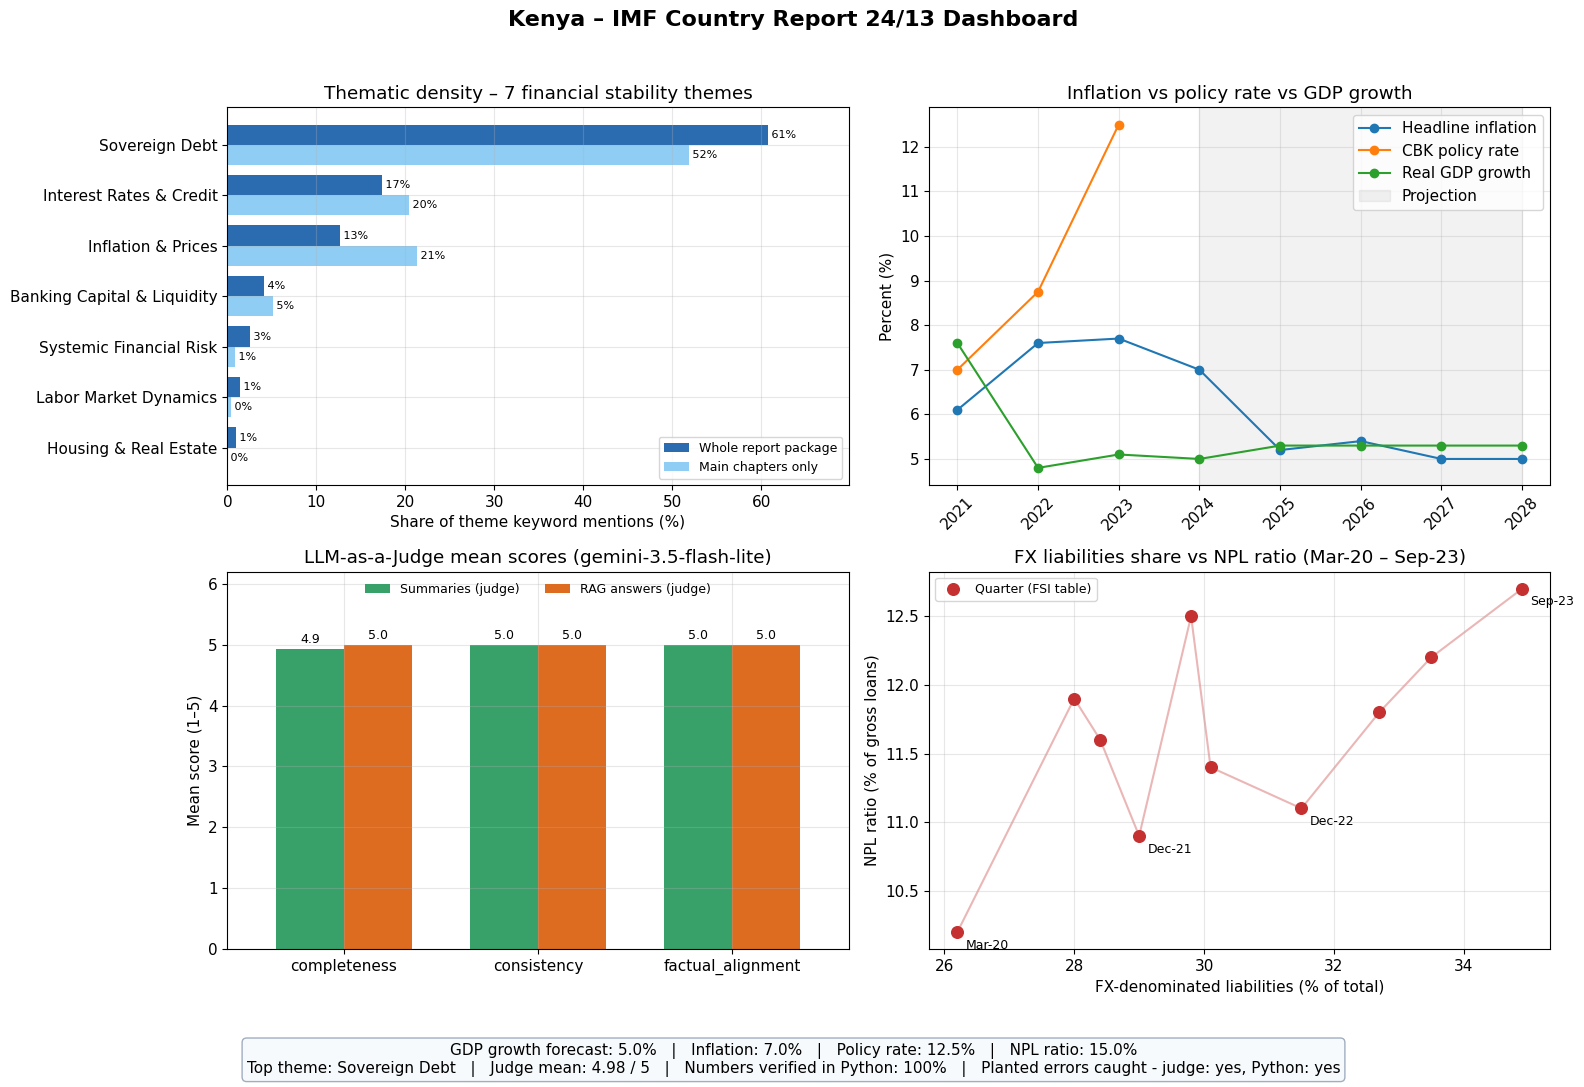

In [68]:
def fmt(k):
    v = indicators[k]
    return "n/a (fallback)" if v == FALLBACK else f"{v:.1f}%"

def caught(after, before):
    """'yes' / 'no' for the planted-error test, or 'not run' when that check had no score."""
    after, before = pd.to_numeric(after, errors="coerce"), pd.to_numeric(before, errors="coerce")
    return "not run" if pd.isna(after) or pd.isna(before) else ("yes" if after < before else "no")

judge_mean = judge_long["score"].mean()
judge_txt = "not run" if pd.isna(judge_mean) else f"{judge_mean:.2f} / 5"

fig, ax = plt.subplots(2, 2, figsize=(16, 11))
plot_themes(ax[0, 0]); plot_trends(ax[0, 1]); plot_judge(ax[1, 0]); plot_fsi(ax[1, 1])
fig.suptitle("Kenya – IMF Country Report 24/13 Dashboard", fontsize=16, weight="bold")

overlay = (f"GDP growth forecast: {fmt('gdp_growth_forecast_pct')}   |   "
           f"Inflation: {fmt('headline_inflation_rate_pct')}   |   "
           f"Policy rate: {fmt('central_bank_policy_rate_pct')}   |   "
           f"NPL ratio: {fmt('non_performing_loan_ratio')}\n"
           f"Top theme: {theme_df.drop(index='Other', errors='ignore')['mentions'].idxmax()}   |   "
           f"Judge mean: {judge_txt}   |   "
           f"Numbers verified in Python: {judge_df['numbers_verified_pct'].mean():.0f}%   |   "
           f"Planted errors caught - judge: {caught(sanity.loc['corrupted', 'factual_alignment'], sanity.loc['original', 'factual_alignment'])}, "
           f"Python: {caught(sanity.loc['corrupted', 'numbers_verified_pct'], sanity.loc['original', 'numbers_verified_pct'])}")
fig.text(0.5, 0.01, overlay, ha="center", va="bottom", fontsize=11,
         bbox=dict(boxstyle="round", facecolor="#f7fafc", edgecolor="#a0aec0"))
fig.tight_layout(rect=[0, 0.07, 1, 0.96])
fig.savefig("figures/dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

**Dashboard panels (all values in percent; figure saved at 300 dpi):**
1. **Thematic density** — share of keyword mentions per theme, whole package vs the 9 main chapters.
2. **Inflation, policy rate and GDP growth** — annual %, shaded area = IMF projections (2024+); gaps = not reported.
3. **LLM-as-a-Judge** — mean 1–5 scores for summaries and RAG answers; read together with the
   planted-error test and the Python number checks in the text box.
4. **FX-denominated liabilities vs NPL ratio** — 10 quarters from the report's Financial Soundness
   Indicators table: each point is a quarter, showing how bank dollarisation and asset quality moved together.

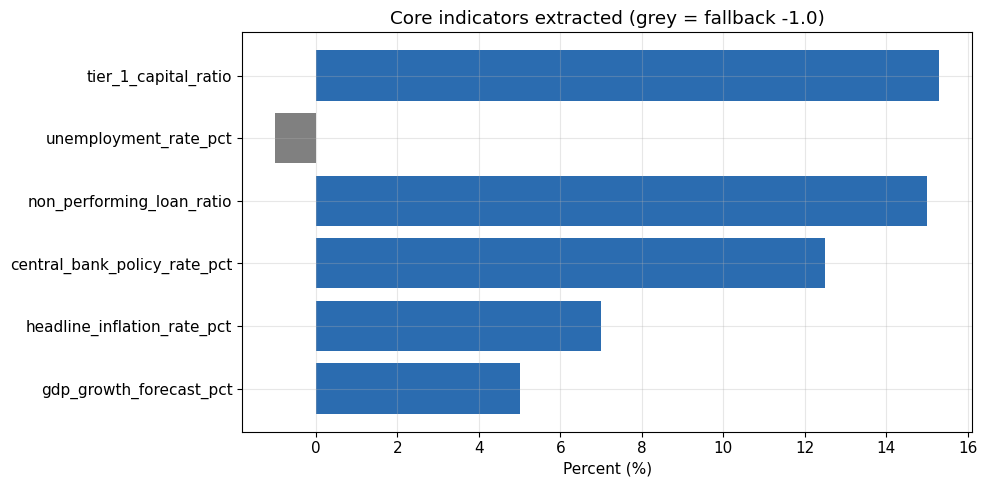

In [69]:
# Extra plot: extracted core indicators (fallbacks shown in grey)
d = ind_long.copy()
colors = ["grey" if v == FALLBACK else "#2b6cb0" for v in d["value"]]
plt.figure(figsize=(10, 5))
plt.barh(d["indicator"], d["value"], color=colors)
plt.title("Core indicators extracted (grey = fallback -1.0)")
plt.xlabel("Percent (%)"); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("figures/core_indicators.png", dpi=300)
plt.show()

## Extension — System-instruction directives vs generic prompts
The same extraction tasks are run two ways:
- **Strict:** a `system_instruction` that sets the analyst role and rules, plus Gemini's JSON mode.
- **Generic:** the task only, as a plain user prompt (no system instruction, no JSON mode).

Compared on **schema compliance** (valid JSON, all keys, correct types), **latency**, and the **judge's accuracy score**.

> Rows marked `not run` (no cached answer and no available model) are excluded from the comparison:
> an empty reply is not a "worse prompt", so it is never scored.

In [70]:
GENERIC_TASKS = {
    "indicators": f"Give me these numbers for Kenya from the report as JSON with keys "
                  f"{list(SCHEMA)}.\n\nREPORT:\n{doc_for_llm}",
    "insights":   f"List Kenya's growth drivers and vulnerabilities from this report as JSON with keys "
                  f"growth_drivers and vulnerabilities.\n\nREPORT:\n{doc_for_llm}",
}
STRICT_TASKS = {"indicators": ind_prompt, "insights": qual_prompt}
REQUIRED = {"indicators": list(SCHEMA), "insights": ["growth_drivers", "vulnerabilities"]}

def schema_check(text, keys):
    """Score one reply: is it valid JSON, are all keys there, are the numbers numbers?"""
    try:
        obj = json.loads(text)
        valid = True
    except Exception:
        obj, valid = to_json(text), False          # rescued only by regex = not compliant
    present = sum(k in obj for k in keys) / len(keys)
    numeric_ok = all(isinstance(obj.get(k), (int, float)) or obj.get(k) is None
                     for k in keys if SCHEMA.get(k) == "float")
    return obj, {"valid_json": valid, "keys_present": round(present, 2), "types_ok": numeric_ok}

In [71]:
bench = []
for mode, tasks in [("strict", STRICT_TASKS), ("generic", GENERIC_TASKS)]:
    for task, prompt in tasks.items():
        if mode == "strict":
            text = safe_ask(prompt, system=SYSTEM_ANALYST, json_mode=True)
        else:
            text = safe_ask(prompt)                       # no system instruction, no JSON mode
        latency = ask_llm.last_latency if text else None   # no stale latency from an earlier call
        row = {"mode": mode, "task": task, "status": "ok" if text else "not run (quota / no key)",
               "latency_s": round(latency, 2) if latency else None}
        if text:                                          # only score replies that exist
            obj, checks = schema_check(text, REQUIRED[task])
            verdict = judge(json.dumps(obj)[:4000], doc_for_llm, f"{task} extraction")
            row.update(checks, judge_accuracy=verdict.get("factual_alignment"))
        bench.append(row)

bench_df = pd.DataFrame(bench)
bench_df.to_json("outputs/directive_benchmark.json", orient="records", indent=2)
bench_df

Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']
Skipped LLM call: All models failed for this prompt: ['gemini-3.5-flash', 'gemini-3.8-flash']


,mode,task,status,latency_s,valid_json,keys_present,types_ok,judge_accuracy
0,strict,indicators,ok,14.73,True,1.0,True,5.0
1,strict,insights,ok,6.47,True,1.0,True,5.0
2,generic,indicators,not run (quota / no key),NaN,NaN,NaN,NaN,NaN
3,generic,insights,not run (quota / no key),NaN,NaN,NaN,NaN,NaN


In [72]:
done = bench_df[bench_df["status"] == "ok"].copy()        # failed calls are reported, not plotted as 0
if done["mode"].nunique() < 2:
    print("Benchmark incomplete - only these modes have replies:", list(done["mode"].unique()),
          "\nRe-run the cell above when the API quota resets.")
else:
    plot_df = (done.assign(valid_json=done["valid_json"].astype(int), types_ok=done["types_ok"].astype(int))
               .melt(id_vars=["mode"], value_vars=["valid_json", "keys_present", "types_ok", "judge_accuracy"],
                     var_name="metric", value_name="value")
               .assign(value=lambda d: pd.to_numeric(d["value"], errors="coerce"))
               .groupby(["metric", "mode"])["value"].mean().unstack())

    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    plot_df.loc[["valid_json", "keys_present", "types_ok"]].plot(kind="bar", ax=ax[0], rot=0, ylim=(0, 1.05))
    ax[0].set_title("Schema compliance (share of replies)"); ax[0].set_ylabel("0 – 1")
    lat = done.groupby("mode")["latency_s"].mean()
    ax[1].bar(lat.index, lat.values, color=["#805ad5", "#38a169"])
    ax[1].set_title("Mean extraction latency"); ax[1].set_ylabel("Seconds")
    for a in ax: a.grid(alpha=0.3)
    fig.suptitle("System-instruction directive vs generic prompt", weight="bold")
    fig.tight_layout(); fig.savefig("figures/directive_benchmark.png", dpi=300)
    plt.show()
    print(plot_df.round(2))

Benchmark incomplete - only these modes have replies: ['strict'] 
Re-run the cell above when the API quota resets.


## Reproducibility check and downloads

In [73]:
# How many LLM answers came from the cache vs live calls in THIS run.
# On the marker's machine (no key) the goal is: every core step = cache_hit.
print("LLM calls this run:", dict(ask_llm_stats))
if ask_llm_stats["unavailable"]:
    print("Some optional steps were skipped (no cached answer) - see the 'not run' rows above.")

# Pin the exact library versions used, for requirements.txt in the repo
import importlib.metadata as md_
# pandas / numpy / matplotlib / requests are left to Colab's own versions: pinning them can
# conflict with the runtime's pre-installed packages.
PKGS = ["pypdf", "tiktoken", "google-genai", "sentence-transformers", "faiss-cpu"]
open("requirements.txt", "w").write("\n".join(f"{p}=={md_.version(p)}" for p in PKGS) + "\n")
print(open("requirements.txt").read())

LLM calls this run: {'cache_hit': 38, 'unavailable': 15, 'live_call': 8}
Some optional steps were skipped (no cached answer) - see the 'not run' rows above.
pypdf==7.0.0
tiktoken==0.14.0
google-genai==2.12.1
sentence-transformers==5.7.0
faiss-cpu==1.15.1



In [74]:
# Files to upload to the GitHub repo so a fresh run needs no key, no quota and no slow embedding
import shutil
shutil.copy(CACHE_PATH, "outputs/gemini_responses.json")   # repo files: this, outputs/embeddings.npz, requirements.txt
for name, folder in [("pipeline_outputs", "outputs"), ("pipeline_figures", "figures")]:
    shutil.make_archive(name, "zip", ".", folder)
try:
    from google.colab import files
    for f in ["pipeline_outputs.zip", "pipeline_figures.zip", "requirements.txt"]:
        files.download(f)
except ImportError:
    print("Not in Colab - the zips and requirements.txt are in the working folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Reproducing these results
Runtime → **Run all** on a fresh runtime with **no API key**: the PDF, `requirements.txt`,
`gemini_responses.json` and `embeddings.npz` are downloaded from the repository, every LLM step is
answered from the cache (the call counter above shows `cache_hit` only), and all tables, JSON
files and figures are regenerated exactly.